# Optimisation à court terme des systèmes électriques — version corrigée


Ce TD aborde quatre problèmes complémentaires :
1. **Marché électrique simple** : dispatch économique, prix marginal, échanges entre zones et stockage ;
2. **Offres d’achat et de vente** : représentation d’un marché par des offres et maximisation du surplus social ;
3. **Réseau de transport (SciGRID)** : dispatch optimal sur un réseau maillé réaliste, prix nodaux, congestion, puis flux de puissance non linéaire ;
4. **Valeur de l’eau** : rôle de la valeur marginale du stock dans la gestion d’un stockage de longue durée.

## Rappel de cours

*Adapté du workshop PyPSA de F. Neumann (TU Berlin). Les symboles de cette section sont repris dans les questions « Lien avec le cours » tout au long du TD.*

### De données structurées à l'optimisation

**Principe de conception de PyPSA : chaque composant est associé à un ensemble de variables et de contraintes, ajoutées automatiquement au modèle d'optimisation à partir des données saisies pour ce composant.**

Pour une simulation de marché de l'électricité (pas de temps horaire), PyPSA résout un problème d'optimisation de la forme suivante :

\begin{equation}
\min_{g_{i,s,t}; f_{\ell,t}; g_{i,r,t,\text{charge}}; g_{i,r,t,\text{discharge}}; e_{i,r,t}} \sum_{i,s,t} o_{i,s}\, g_{i,s,t}
\end{equation}

sous les contraintes :

\begin{align}
0 & \leq g_{i,s,t} \leq \hat{g}_{i,s,t} G_{i,s}  & \text{limites de production : générateur} \\
-F_\ell &\leq f_{\ell,t} \leq F_\ell & \text{limites de transmission : ligne}  \\
d_{i,t} &= \sum_s g_{i,s,t} + \sum_r g_{i,r,t,\text{discharge}} - \sum_r g_{i,r,t,\text{charge}} - \sum_\ell K_{i\ell} f_{\ell,t} & \text{KCL : bilan nodal} \\
 0 &=\sum_\ell C_{\ell c} x_\ell f_{\ell,t} & \text{KVL : cycles du réseau} \\
0 & \leq g_{i,r,t,\text{discharge}} \leq G_{i,r,\text{discharge}}& \text{limites de décharge : stockage} \\
0 & \leq g_{i,r,t,\text{charge}} \leq G_{i,r,\text{charge}} & \text{limites de charge : stockage} \\
0 & \leq e_{i,r,t} \leq E_{i,r} & \text{limites d'énergie : stockage} \\
e_{i,r,t} &= \eta^0_{i,r,t} e_{i,r,t-1} + \eta^1_{i,r,t}g_{i,r,t,\text{charge}} -  \frac{1}{\eta^2_{i,r,t}} g_{i,r,t,\text{discharge}} & \text{consistance : stockage} \\
e_{i,r,0} & = e_{i,r,|T|-1}  & \text{cyclicité : stockage}
\end{align}

(Dans cette écriture, chaque pas de temps dure une heure ; dans le cas général, le coût d'exploitation est pondéré par la durée $w_t$ représentée par le pas de temps.)

**Variables de décision :**

- $g_{i,s,t}$ : production du générateur de technologie $s$ au nœud $i$ au pas de temps $t$ ;
- $f_{\ell,t}$ : flux de puissance sur la ligne $\ell$ ;
- $g_{i,r,t,\text{charge/discharge}}$ : charge et décharge de l'unité de stockage $r$ au nœud $i$ ;
- $e_{i,r,t}$ : état de charge du stockage $r$ au nœud $i$.

**Paramètres :**

- $o_{i,s}$ : coût marginal de production de la technologie $s$ au nœud $i$ ;
- $d_{i,t}$ : demande au nœud $i$ ;
- $x_\ell$ : réactance de la ligne $\ell$ ;
- $K_{i\ell}$ : matrice d'incidence nœuds-lignes ;
- $C_{\ell c}$ : matrice des cycles ;
- $G_{i,s}$ : capacité nominale du générateur ; $\hat{g}_{i,s,t}$ : disponibilité en pourcentage de la capacité (profil de vent ou de soleil) ;
- $F_{\ell}$ : capacité de transmission de la ligne $\ell$ ;
- $E_{i,r}$ : capacité énergétique du stockage ; $G_{i,r,\text{charge/discharge}}$ : puissances de charge et de décharge ;
- $\eta^{0/1/2}_{i,r,t}$ : rendements de maintien (0), de charge (1) et de décharge (2).

**Variables duales (prix).** À chaque contrainte est associée une variable duale. Celle du bilan nodal (KCL), $\lambda_{i,t}$, est le **prix marginal** (ou prix nodal, LMP) : le coût d'un MWh supplémentaire consommé au nœud $i$ au pas de temps $t$. Celles des limites de production et de transmission mesurent la valeur d'un MW de capacité supplémentaire (rente des centrales, rente de congestion).

### Correspondance entre symboles et attributs PyPSA

| Symbole | Dans PyPSA |
|---|---|
| $g_{i,s,t}$ | `n.generators_t.p` |
| $o_{i,s}$ | `marginal_cost` du générateur |
| $G_{i,s}$ ; $\hat{g}_{i,s,t}$ | `p_nom` ; `p_max_pu` |
| $d_{i,t}$ | `p_set` de la charge |
| $f_{\ell,t}$ ; $F_\ell$ ; $x_\ell$ | `n.lines_t.p0` ; `s_nom` (x `s_max_pu`) ; `x` |
| $g_{i,r,t,\text{charge/discharge}}$ ; $e_{i,r,t}$ | `n.storage_units_t.p` ; `n.storage_units_t.state_of_charge` |
| $E_{i,r}$ | `p_nom` x `max_hours` |
| $\eta^{1}$ ; $\eta^{2}$ | `efficiency_store` ; `efficiency_dispatch` |
| $\lambda_{i,t}$ | `n.buses_t.marginal_price` |

Pour une description complète du problème d'optimisation, voir la [documentation de PyPSA](https://docs.pypsa.org/latest/user-guide/optimization/overview/).

### Où retrouver ces équations dans le TD

| Exercice | Éléments de la formulation mobilisés |
|---|---|
| 1. Marché simple | limites de production, bilan nodal, stockage ; prix = variable duale du bilan |
| 2. Offres d'achat et de vente | mêmes équations avec un générateur de signe négatif ; surplus social |
| 3. Réseau (SciGRID) | limites de transmission, KCL et KVL (flux continu), prix nodaux |
| 4. Valeur de l'eau | consistance du stockage et valeur duale de l'énergie stockée |

## Préparation commune

In [3]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa

warnings.filterwarnings("ignore", category=DeprecationWarning)
pypsa.options.params.optimize.log_to_console = False

print("Version de PyPSA :", pypsa.__version__)

import logging

logging.getLogger("pypsa").setLevel(logging.ERROR)     # messages d'information masqués (on relance beaucoup de calculs)
logging.getLogger("linopy").setLevel(logging.WARNING)  # on garde les alertes, par exemple en cas d'infaisabilité


def copier_reseau(n):
    """Copie un réseau, y compris s'il a déjà été optimisé.

    Dans les versions récentes de PyPSA, `n.copy()` refuse de copier un réseau résolu
    tant que le modèle du solveur est attaché : on le détache d'abord.
    """
    if getattr(n, "model", None) is not None:
        n.model.solver_model = None
    return n.copy()


Version de PyPSA : 1.2.4


In [4]:
#**Compiler ce code si problème de chemin temporaire** 
import os
import tempfile

os.environ["TEMP"] = r"C:\Temp"
os.environ["TMP"] = r"C:\Temp"

tempfile.tempdir = None

print(tempfile.gettempdir())

C:\Temp


---

# Exercice 1 — Marché électrique simple

## Objectifs

- Comprendre comment le coût marginal des centrales détermine l’ordre d’appel ;
- relier le dispatch économique au prix marginal de l’électricité ;
- observer l’effet des échanges entre zones de marché ;
- étudier la demande flexible, les variations temporelles et le stockage.

Dans ce modèle simplifié, les centrales sont représentées par des générateurs de puissance maximale donnée et de coût marginal constant. La demande classique est supposée inélastique : elle doit être satisfaite. Les capacités et consommations sont pédagogiques et ne représentent pas fidèlement les systèmes électriques réels.


## 1.1 Données du système

Les coûts sont exprimés en €/MWh et les puissances en MW. On considère cinq technologies : éolien, hydraulique, charbon, gaz et pétrole.

In [22]:
# Coûts marginaux en €/MWh
couts_marginaux = {
    "Wind": 0,
    "Hydro": 0,
    "Coal": 30,
    "Gas": 60,
    "Oil": 80,
}

# Puissances installées par zone (MW)
capacites = {
    "South Africa": {"Coal": 35000, "Wind": 3000, "Gas": 8000, "Oil": 2000},
    "Mozambique": {"Hydro": 1200},
    "Eswatini": {"Hydro": 600},
}

# Capacités d'interconnexion (MW)
interconnexions = {
    "South Africa": {"Mozambique": 500, "Eswatini": 250},
    "Mozambique": {"Eswatini": 100},
}

# Demande par zone (MW)
demandes = {"South Africa": 42000, "Mozambique": 650, "Eswatini": 250}

## 1.2 Une seule zone de marché, une période

On commence par l’Afrique du Sud. Le modèle minimise le coût total du système qui satisfait la demande.

In [23]:
# TODO : construire le réseau d'une seule zone (South Africa) et le résoudre.

### DEBUT SOLUTION
zone = "South Africa"
# Réseau vide : conteneur de tous les composants (bus, générateurs, charges, liens...)
n = pypsa.Network()
# Bus = nœud du réseau : tous les composants s'y raccordent et y respectent l'équilibre offre-demande
n.add("Bus", zone)

for technologie, puissance in capacites[zone].items():
    # Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
    n.add(
        "Generator",
        f"{zone} {technologie}",
        bus=zone,
        p_nom=puissance,
        marginal_cost=couts_marginaux[technologie],
    )

# Load = demande à satisfaire (p_set : puissance consommée, en MW)
n.add("Load", f"{zone} demande", bus=zone, p_set=demandes[zone])
# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n.optimize(solver_name="highs")
### FIN SOLUTION


C:\Temp\ipykernel_129132\463377186.py:23: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs")


('ok', 'optimal')

Examinons les capacités, la production et le prix marginal obtenus.

In [24]:
# TODO : afficher les résultats utiles à l'analyse.
### DEBUT SOLUTION
display(n.generators[["bus", "p_nom", "marginal_cost"]])
# Production de chaque générateur (MW) : lignes = pas de temps, colonnes = générateurs
display(n.generators_t.p)
display(n.loads_t.p)
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
display(n.buses_t.marginal_price)
### FIN SOLUTION


,bus,p_nom,marginal_cost
name,,,
South Africa Coal,South Africa,35000.0,30.0
South Africa Wind,South Africa,3000.0,0.0
South Africa Gas,South Africa,8000.0,60.0
South Africa Oil,South Africa,2000.0,80.0


name,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil
snapshot,,,,
now,35000.0,3000.0,4000.0,-0.0


name,South Africa demande
snapshot,
now,42000.0


name,South Africa
snapshot,
now,60.0


**Questions**

1. Quelle est la centrale marginale et que vaut le prix marginal ? Le charbon produit à pleine puissance : pourquoi ne fixe-t-il pas le prix ?
2. Que vaudrait le prix si la demande était de 30 000 MW ? de 47 000 MW ?
3. D'où vient le prix marginal de l'électricité dans notre problème ? Comment l'interpréter ?
4. Le prix marginal est-il égal au coût moyen de production ?

**Lien avec le cours :** dispatch économique et ordre de mérite ; le prix marginal est la variable duale de la contrainte d'équilibre offre-demande ([Rappel de cours](#Rappel-de-cours), contrainte « bilan nodal »).

**Éléments de réponse** *(cellule de correction)*

1. Le gaz est la centrale marginale : le prix vaut 60 €/MWh. Le charbon est à sa limite de capacité (35 000 MW) ; une centrale saturée fixe son rentabilité (rente) mais pas le prix : celui-ci est fixé par la centrale qui ajuste sa production à la marge, ici le gaz (4 000 MW appelés sur 8 000).
2. À 30 000 MW la demande est couverte par l'éolien et une partie du charbon : le prix serait de 30 €/MWh ; à 47 000 MW il faut du pétrole, le prix serait de 80 €/MWh.
3. Le prix marginal est la variable duale de la contraintre d'équimibre au noeud. Elle indique le coût supplémentaire si l'on consommait 1 MWh de plus au noeud. 
4. Non : le coût moyen vaut environ 30,7 €/MWh ((35 000 x 30 + 4 000 x 60) / 42 000) alors que le prix est de 60 €/MWh. Le prix marginal rémunère aussi les centrales moins chères (rentes inframarginales) qui couvrent ainsi leurs coûts fixes.

## 1.3 Deux zones reliées par une interconnexion

On ajoute le Mozambique, qui dispose d’une centrale hydraulique peu coûteuse. Un `Link` représente ici une interconnexion contrôlable et sans pertes (pas de loi de Kirchoff). Le paramètre `p_min_pu=-1` autorise un flux dans les deux sens.

In [25]:
# TODO : construire et résoudre le réseau à deux zones (Mozambique, South Africa).
#  - un bus, des générateurs et une charge par zone (comme en 1.2) ;
#  - ajouter un Link "South Africa - Mozambique" de 500 MW avec p_min_pu=-1 (flux possible dans les deux sens) ;
#  - résoudre avec n.optimize(solver_name="highs").
### DEBUT SOLUTION
# Réseau vide : conteneur de tous les composants (bus, générateurs, charges, liens...)
n = pypsa.Network()
zones = ["Mozambique", "South Africa"]

for zone in zones:
    # Bus = nœud du réseau : tous les composants s'y raccordent et y respectent l'équilibre offre-demande
    n.add("Bus", zone)
    for technologie, puissance in capacites[zone].items():
        # Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
        n.add(
            "Generator",
            f"{zone} {technologie}",
            bus=zone,
            p_nom=puissance,
            marginal_cost=couts_marginaux[technologie],
        )
    # Load = demande à satisfaire (p_set : puissance consommée, en MW)
    n.add("Load", f"{zone} demande", bus=zone, p_set=demandes[zone])

for zone, voisins in interconnexions.items():
    if zone not in zones:
        continue
    for voisin, puissance in voisins.items():
        if voisin in zones:
            # Link = élément de transport ou de conversion de bus0 vers bus1 (efficiency : rendement ; p_min_pu=-1 autorise le flux dans les deux sens)
            n.add(
                "Link", f"{zone} - {voisin}",
                bus0=zone, bus1=voisin,
                p_nom=puissance, p_min_pu=-1,
            )

# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n.optimize(solver_name="highs",assign_all_duals=True)
### FIN SOLUTION


C:\Temp\ipykernel_129132\3254096392.py:38: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs",assign_all_duals=True)


('ok', 'optimal')

In [26]:
# TODO : afficher la production/consommation, les prix marginaux des deux zones, le flux sur le lien (links_t.p0)
# les variables duales associées au lien (links_t.mu_lower, links_t.mu_upper) et la valeur objectif.
### DEBUT SOLUTION
# Production de chaque générateur (MW) : lignes = pas de temps, colonnes = générateurs
display(n.generators_t.p)
display(n.loads_t.p)
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
display(n.buses_t.marginal_price)
# Flux sur les liens (MW), compté de bus0 vers bus1 : négatif = de bus1 vers bus0
display(n.links_t.p0)
# mu_lower : variable duale de la limite inférieure du flux (non nulle si le lien est saturé dans le sens négatif)
display(n.links_t.mu_lower)
display(n.links_t.mu_upper)
# valeur objectif à l'optimal 
display(n.objective)
### FIN SOLUTION


name,Mozambique Hydro,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil
snapshot,,,,,
now,1150.0,35000.0,3000.0,3500.0,-0.0


name,Mozambique demande,South Africa demande
snapshot,,
now,650.0,42000.0


name,Mozambique,South Africa
snapshot,,
now,-0.0,60.0


name,South Africa - Mozambique
snapshot,
now,-500.0


name,South Africa - Mozambique
snapshot,
now,60.0


name,South Africa - Mozambique
snapshot,
now,-0.0


1260000.0

**Questions**

1. Quel est le sens et la valeur du flux sur le lien ? Le lien est-il saturé ?
2. Pourquoi les prix diffèrent-ils entre les deux zones ?
3. Que représente l'écart de prix ? Comment interpréter les variables duales associées aux bornes du lien ?
4. Qu'est ce que la rente de congestion ? Combien vaut elle ici ? 
5. Que deviendraient les prix si la capacité du lien passait à 800 MW ?
6. Comment interpréter la valeur de la fonction objectif ? 

**Éléments de réponse** *(cellule de correction)*

1. 500 MW sont exportés du Mozambique vers l'Afrique du Sud (flux négatif sur un lien déclaré de l'Afrique du Sud vers le Mozambique). Le lien est saturé : son flux est égal à sa capacité.
2. Le Mozambique a un excédent d'hydraulique bon marché qu'il ne peut pas exporter davantage : son prix est de 0 €/MWh, celui de l'Afrique du Sud de 60 €/MWh.
3. L'écart (60 €/MWh) mesure la valeur d'un MW de capacité de transport supplémentaire. La variable duale associée à la borne haute vaut 0 car la contrainte n'est pas active. La variable associé à la borne basse vaut 60 €/MWh, elle représente le coût associé à l'accroissement de +epsilon de capacité (-Fl + epsilon = contrainte durcie, donc surcoût).
4. La rente de congestion est la rentre perçue par l'opérateur de réseau lorsque que l'une de ses lignes est saturée. Ici elle vaut 60 €/MWh * 500 MW = 30 000 €/h
5. Avec 800 MW, la capacité dépasse l'excédent exportable (environ 550 MW) : le lien n'est plus saturé et les deux prix s'égalisent à 60 €/MWh (l'hydraulique est alors entièrement utilisée).
6. C'est le coût total du sytème 

## 1.4 Trois zones reliées

On ajoute l’Eswatini et ses capacités hydrauliques. La structure de code reste la même : création des bus, ajout des centrales et des demandes, puis ajout des interconnexions présentes entre les zones étudiées.

In [27]:
# TODO : construire et résoudre le réseau à trois zones (Eswatini, Mozambique, South Africa).
#  - même structure qu'en 1.3 (un bus, des générateurs et une charge par zone) ;
#  - ajouter les liens entre zones avec leurs capacités (p_min_pu=-1) ;
#  - résoudre avec n.optimize(solver_name="highs").
### DEBUT SOLUTION
# Réseau vide : conteneur de tous les composants (bus, générateurs, charges, liens...)
n = pypsa.Network()
zones = ["Eswatini", "Mozambique", "South Africa"]

for zone in zones:
    # Bus = nœud du réseau : tous les composants s'y raccordent et y respectent l'équilibre offre-demande
    n.add("Bus", zone)
    for technologie, puissance in capacites[zone].items():
        # Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
        n.add(
            "Generator",
            f"{zone} {technologie}",
            bus=zone,
            p_nom=puissance,
            marginal_cost=couts_marginaux[technologie],
        )
    # Load = demande à satisfaire (p_set : puissance consommée, en MW)
    n.add("Load", f"{zone} demande", bus=zone, p_set=demandes[zone])

for zone, voisins in interconnexions.items():
    for voisin, puissance in voisins.items():
        if zone in zones and voisin in zones:
            # Link = élément de transport ou de conversion de bus0 vers bus1 (efficiency : rendement ; p_min_pu=-1 autorise le flux dans les deux sens)
            n.add(
                "Link", f"{zone} - {voisin}",
                bus0=zone, bus1=voisin,
                p_nom=puissance, p_min_pu=-1,
            )

# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n.optimize(solver_name="highs", assign_all_duals=True)
### FIN SOLUTION

C:\Temp\ipykernel_129132\1969283219.py:36: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs", assign_all_duals=True)


('ok', 'optimal')

In [29]:
# TODO : afficher la production/consommation, les prix marginaux, les flux sur les liens (links_t.p0) et les duales.
### DEBUT SOLUTION
# Production de chaque générateur (MW) : lignes = pas de temps, colonnes = générateurs
display(n.generators_t.p)
display(n.loads_t.p)
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
display(n.buses_t.marginal_price)
# Flux sur les liens (MW), compté de bus0 vers bus1 : négatif = de bus1 vers bus0
display(n.links_t.p0)
# mu_lower : variable duale de la limite inférieure du flux (non nulle si le lien est saturé dans le sens négatif)
display(n.links_t.mu_upper)
display(n.links_t.mu_lower)
# objectif 
display(n.objective)
### FIN SOLUTION


name,Eswatini Hydro,Mozambique Hydro,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil
snapshot,,,,,,
now,600.0,1050.0,35000.0,3000.0,3250.0,-0.0


name,Eswatini demande,Mozambique demande,South Africa demande
snapshot,,,
now,250.0,650.0,42000.0


name,Eswatini,Mozambique,South Africa
snapshot,,,
now,-0.0,-0.0,60.0


name,South Africa - Mozambique,South Africa - Eswatini,Mozambique - Eswatini
snapshot,,,
now,-500.0,-250.0,-100.0


name,South Africa - Mozambique,South Africa - Eswatini,Mozambique - Eswatini
snapshot,,,
now,-0.0,-0.0,-0.0


name,South Africa - Mozambique,South Africa - Eswatini,Mozambique - Eswatini
snapshot,,,
now,60.0,60.0,-0.0


1245000.0

**Questions**

1. Dans quelles zones le prix est-il nul et pourquoi ?
2. Comparez avec le cas à deux zones : que change l'ajout d'Eswatini pour l'Afrique du Sud (production de gaz, prix) ?
3. Qu'est-ce qui empêche les prix des trois zones de s'égaliser ? Comment interpréter les duales ?
4. Comparer le coût total des deux systèmes.

**Éléments de réponse** *(cellule de correction)*

1. Eswatini et Mozambique ont un prix nul : elles disposent d'un excédent d'hydraulique (coût marginal nul) qu'elles ne peuvent pas évacuer entièrement.
2. La production de gaz sud-africaine baisse (environ 3 250 MW au lieu de 3 500 MW) car l'Afrique du Sud importe davantage ; le prix reste cependant à 60 €/MWh car le gaz reste marginal. Pour les duales l'interprétation est la même. 
3. Les liens saturés : tant que les capacités de transfert sont inférieures à l'excédent exportable, l'hydraulique est « bloquée » dans ses zones et les prix restent différents.

## 1.5 Demande industrielle sensible au prix

La demande industrielle élastique est modélisée comme un générateur à dispatch négatif : une production négative correspond à une consommation. Son coût marginal négatif représente l’utilité marginale de la consommation.

In [31]:
# TODO : reprendre le réseau à une zone de 1.2 et ajouter une demande industrielle élastique.
#  - une Load inélastique de 42 000 MW (déjà présente en 1.2) ;
#  - un générateur "South Africa demande industrielle" de 8 000 MW avec marginal_cost = 70 (utilité marginale en €/MWh) ;
#  - résoudre.
### DEBUT SOLUTION
zone = "South Africa"
# Réseau vide : conteneur de tous les composants (bus, générateurs, charges, liens...)
n = pypsa.Network()
# Bus = nœud du réseau : tous les composants s'y raccordent et y respectent l'équilibre offre-demande
n.add("Bus", zone)

for technologie, puissance in capacites[zone].items():
    # Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
    n.add(
        "Generator", f"{zone} {technologie}",
        bus=zone, p_nom=puissance,
        marginal_cost=couts_marginaux[technologie],
    )

# Load = demande à satisfaire (p_set : puissance consommée, en MW)
n.add("Load", f"{zone} demande inélastique", bus=zone, p_set=demandes[zone])
n.add(
    "Generator", f"{zone} demande industrielle",
    bus=zone, p_nom=8000,
    p_max_pu=0, p_min_pu=-1,
    marginal_cost=70,
)
# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n.optimize(solver_name="highs", assign_all_duals=True)
### FIN SOLUTION


C:\Temp\ipykernel_129132\1152212351.py:29: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs", assign_all_duals=True)


('ok', 'optimal')

In [32]:
# TODO : afficher la production de chaque générateur (la demande industrielle apparaît en négatif) et le prix marginal.
### DEBUT SOLUTION
# Production de chaque générateur (MW) : lignes = pas de temps, colonnes = générateurs
display(n.generators_t.p)
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
display(n.buses_t.marginal_price)
### FIN SOLUTION


name,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil,South Africa demande industrielle
snapshot,,,,,
now,35000.0,3000.0,8000.0,-0.0,-4000.0


name,South Africa
snapshot,
now,70.0


**Questions d'observation**

1. Pourquoi le prix vaut-il 70 €/MWh alors qu'aucune centrale n'a ce coût marginal ?
2. Quelle quantité la demande industrielle consomme-t-elle ? Pourquoi pas ses 8 000 MW ?
3. Que se passerait-il avec une utilité marginale de 50 €/MWh ?

**Éléments de réponse** *(cellule de correction)*

1. Le gaz restant (4 000 MW) est entièrement utilisé ; aller au-delà nécessiterait du pétrole à 80 €/MWh, au-dessus de l'utilité de 70 €/MWh. Le consommateur industriel est donc le consommateur marginal : le prix est fixé par sa disposition à payer (toutes les centrales sont saturées, aucune n'est marginale).
2. Elle consomme 4 000 MW, soit le gaz encore disponible : servir plus coûterait plus (80 €/MWh) que ce qu'elle est prête à payer.
3. Avec 50 €/MWh, inférieur au coût du gaz (60), la demande industrielle ne consomme rien et le prix revient à 60 €/MWh.

## 1.6 Plusieurs périodes : demande et vent variables

On considère quatre périodes. La disponibilité du vent varie, tout comme la demande. Cela permet d’observer des prix marginaux différents d’une période à l’autre.

In [34]:
# TODO : construire un réseau à 4 pas de temps (n.set_snapshots(range(4))) pour l'Afrique du Sud.
#  - générateurs comme en 1.2, avec un facteur de charge = [0.3, 0.6, 0.4, 0.5] pour l'éolien (1 pour les autres) ;
#  - une charge variable : 42 000 MW + [0, 1 000, 3 000, 4 000] MW ;
#  - résoudre.
### DEBUT SOLUTION
zone = "South Africa"
# Réseau vide : conteneur de tous les composants (bus, générateurs, charges, liens...)
n = pypsa.Network()
n.set_snapshots(range(4))
# Bus = nœud du réseau : tous les composants s'y raccordent et y respectent l'équilibre offre-demande
n.add("Bus", zone)

for technologie, puissance in capacites[zone].items():
    # Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
    n.add(
        "Generator", f"{zone} {technologie}",
        bus=zone, p_nom=puissance,
        marginal_cost=couts_marginaux[technologie],
        p_max_pu=([0.3, 0.6, 0.4, 0.5] if technologie == "Wind" else 1),
    )

# Load = demande à satisfaire (p_set : puissance consommée, en MW)
n.add(
    "Load", f"{zone} demande",
    bus=zone,
    p_set=demandes[zone] + np.array([0, 1000, 3000, 4000]),
)
# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n.optimize(solver_name="highs", assign_all_duals=True)
### FIN SOLUTION

C:\Temp\ipykernel_129132\3491921907.py:29: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs", assign_all_duals=True)


('ok', 'optimal')

In [35]:
# TODO : afficher la production de chaque générateur et le prix marginal à chaque pas de temps.
### DEBUT SOLUTION
# Production de chaque générateur (MW) : lignes = pas de temps, colonnes = générateurs
display(n.generators_t.p)
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
display(n.buses_t.marginal_price)
### FIN SOLUTION

name,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil
snapshot,,,,
0,35000.0,900.0,6100.0,-0.0
1,35000.0,1800.0,6200.0,-0.0
2,35000.0,1200.0,8000.0,800.0
3,35000.0,1500.0,8000.0,1500.0


name,South Africa
snapshot,
0,60.0
1,60.0
2,80.0
3,80.0


**Questions d'observation**

1. À quelles périodes le pétrole est-il appelé, et que valent les prix ?
2. Pourquoi les prix sont-ils identiques aux périodes 0 et 1 malgré une demande et un vent différents ?
3. Pourquoi le prix varie-t-il d'une période à l'autre alors que les capacités sont les mêmes ?

**Éléments de réponse** *(cellule de correction)*

1. Aux périodes 2 et 3 (respectivement 800 et 1 500 MW de pétrole) : le prix y vaut 80 €/MWh.
2. Aux périodes 0 et 1, la demande résiduelle après éolien (environ 41 100 et 41 200 MW) est couverte par le charbon et une partie du gaz : le gaz est marginal dans les deux cas, donc le prix est de 60 €/MWh.
3. Le prix est celui de la centrale marginale, qui change avec la demande résiduelle (demande moins éolien) : le système n'est pas contraint de la même façon à chaque période.

## 1.7 Plusieurs périodes avec stockage

On ajoute une unité de stockage hydraulique par pompage. Elle peut charger lorsque l’électricité est relativement peu chère et décharger lorsque le système est tendu. Sa capacité énergétique vaut ici `p_nom × max_hours`.

In [37]:
# TODO : reprendre le modèle à 4 pas de temps de 1.6 et ajouter un stockage par pompage-turbinage.
#  - un StorageUnit de 1 000 MW avec max_hours=6 (6 h d'énergie) ;
#  - résoudre.
### DEBUT SOLUTION
zone = "South Africa"
# Réseau vide : conteneur de tous les composants (bus, générateurs, charges, liens...)
n = pypsa.Network()
n.set_snapshots(range(4))
# Bus = nœud du réseau : tous les composants s'y raccordent et y respectent l'équilibre offre-demande
n.add("Bus", zone)

for technologie, puissance in capacites[zone].items():
    # Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
    n.add(
        "Generator", f"{zone} {technologie}",
        bus=zone, p_nom=puissance,
        marginal_cost=couts_marginaux[technologie],
        p_max_pu=([0.3, 0.6, 0.4, 0.5] if technologie == "Wind" else 1),
    )

# Load = demande à satisfaire (p_set : puissance consommée, en MW)
n.add(
    "Load", f"{zone} demande",
    bus=zone,
    p_set=demandes[zone] + np.array([0, 1000, 3000, 4000]),
)
# StorageUnit = stockage dont l'énergie est liée à la puissance (max_hours : durée de décharge à pleine puissance)
n.add(
    "StorageUnit", f"{zone} pompage-turbinage",
    bus=zone, p_nom=1000, max_hours=6,
)
# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n.optimize(solver_name="highs", assign_all_duals = True)
### FIN SOLUTION


C:\Temp\ipykernel_129132\1429472854.py:33: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs", assign_all_duals = True)


('ok', 'optimal')

In [38]:
# TODO : afficher la production, la puissance du stockage (storage_units_t.p, négative = charge),
# l'état de charge (storage_units_t.state_of_charge) et les prix marginaux.
### DEBUT SOLUTION
# Production de chaque générateur (MW) : lignes = pas de temps, colonnes = générateurs
display(n.generators_t.p)
# Puissance du stockage (MW) : positive = décharge, négative = charge
display(n.storage_units_t.p)
# État de charge du stockage (MWh)
display(n.storage_units_t.state_of_charge)
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
display(n.buses_t.marginal_price)
### FIN SOLUTION


name,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil
snapshot,,,,
0,35000.0,900.0,6900.0,-0.0
1,35000.0,1800.0,7200.0,-0.0
2,35000.0,1200.0,8000.0,-0.0
3,35000.0,1500.0,8000.0,500.0


name,South Africa pompage-turbinage
snapshot,
0,-800.0
1,-1000.0
2,800.0
3,1000.0


name,South Africa pompage-turbinage
snapshot,
0,800.0
1,1800.0
2,1000.0
3,-0.0


name,South Africa
snapshot,
0,60.0
1,60.0
2,60.0
3,80.0


**Questions d'observation**

1. Quand le stockage charge-t-il et décharge-t-il, et pourquoi ?
2. Comparez les prix et l'utilisation du pétrole avec le cas sans stockage (1.6).
3. Le stockage fait-il baisser le prix à toutes les périodes ?

**Éléments de réponse** *(cellule de correction)*

1. Il charge aux périodes 0 et 1 (prix bas) et décharge aux périodes 2 et 3 (prix élevés) : c'est de l'arbitrage temporel entre périodes de coût marginal différent.
2. Le pétrole n'est plus appelé qu'à la période 3 (500 MW au lieu de 800 et 1 500 MW) ; le prix de la période 2 passe de 80 à 60 €/MWh, celui de la période 3 reste à 80 €/MWh.
3. Non : le stockage augmente la demande aux périodes de charge et la diminue aux périodes de décharge. Ici le prix de charge reste à 60 €/MWh (gaz marginal), celui de la période 2 baisse, celui de la période 3 ne change pas.

## 1.8 Pour explorer : ordre de mérite, interconnexions, demande flexible, éolien et stockage

Pour faire varier facilement un paramètre, on encapsule la construction du réseau de l'Afrique du Sud dans une fonction (fournie). Elle peut ajouter une **centrale de délestage** fictive (coût très élevé) qui représente la demande non servie : sans elle, le modèle est infaisable quand la demande dépasse la capacité installée.

In [40]:
def reseau_afrique_du_sud(demande=42000, delestage=True, p_nom_vent=None, stockage=0, utilite_industrie=None, quatre_periodes=False):
    """Réseau de l'Afrique du Sud (un bus). Options :
    - delestage : ajoute une centrale de délestage à 1000 €/MWh ;
    - p_nom_vent : remplace la capacité éolienne installée ;
    - stockage : puissance (MW) d'un stockage par pompage de 6 h ;
    - utilite_industrie : ajoute une demande industrielle flexible de 8000 MW avec cette utilité marginale (€/MWh) ;
    - quatre_periodes : 4 périodes avec demande et vent variables (comme en 1.6).
    """
    zone = "South Africa"
    m = pypsa.Network()
    if quatre_periodes:
        m.set_snapshots(range(4))
    m.add("Bus", zone)
    for technologie, puissance in capacites[zone].items():
        options = {}
        if technologie == "Wind":
            puissance = p_nom_vent if p_nom_vent is not None else puissance
            if quatre_periodes:
                options["p_max_pu"] = [0.3, 0.6, 0.4, 0.5]
        m.add("Generator", f"{zone} {technologie}", bus=zone, p_nom=puissance,
              marginal_cost=couts_marginaux[technologie], **options)
    if delestage:
        m.add("Generator", "délestage", bus=zone, p_nom=50000, marginal_cost=1000)
    charge = demande + np.array([0, 1000, 3000, 4000]) if quatre_periodes else demande
    m.add("Load", "demande", bus=zone, p_set=charge)
    if utilite_industrie is not None:
        m.add("Generator", "demande industrielle", bus=zone, p_nom=8000,
              p_max_pu=0, p_min_pu=-1, marginal_cost=utilite_industrie)
    if stockage:
        m.add("StorageUnit", "pompage", bus=zone, p_nom=stockage, max_hours=6)
    m.optimize(solver_name="highs")
    return m


def tracer_ordre_de_merite(demande):
    """Ordre de mérite de l'Afrique du Sud : capacités cumulées en abscisse, coût marginal en ordonnée."""
    zone = "South Africa"
    techs = sorted(capacites[zone], key=lambda t: couts_marginaux[t])
    fig, ax = plt.subplots(figsize=(7, 3.5))
    debut = 0
    for t in techs:
        ax.bar(debut / 1e3, couts_marginaux[t], width=capacites[zone][t] / 1e3, align="edge", alpha=0.6, edgecolor="k", label=t)
        debut += capacites[zone][t]
    ax.axvline(demande / 1e3, color="r", ls="--", label="Demande")
    ax.set_xlabel("Capacité cumulée (GW)")
    ax.set_ylabel("Coût marginal (€/MWh)")
    ax.legend()
    plt.show()

### 1.8.a Ordre de mérite et prix en fonction de la demande

Le prix marginal est égal au coût marginal de la **centrale marginale** ou du **consommateur marginal**, donc il dépend de la position de la demande sur la courbe d'ordre de mérite. On trace d'abord cette courbe pour la demande de référence, puis le prix en faisant **varier la demande**.

> **Prédisez** le prix pour une demande de 37 000 MW, 46 500 MW et 50 000 MW.

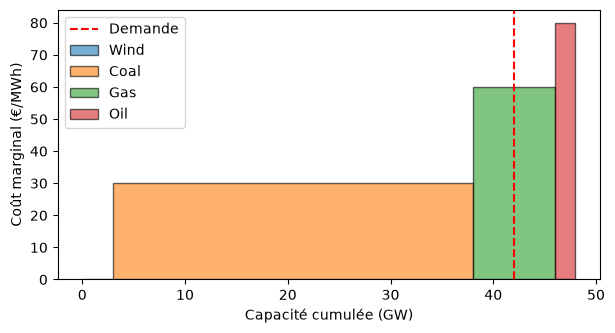

C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")
C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")
C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not

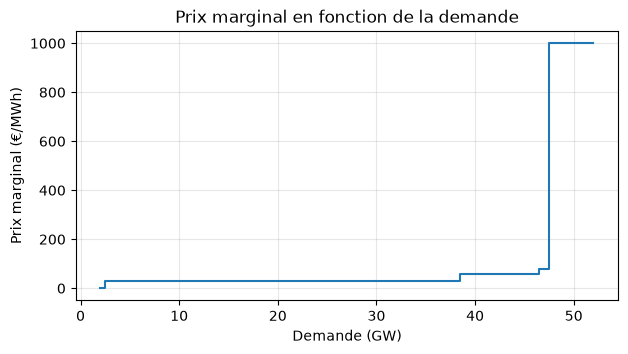

In [41]:
# TODO : (1) tracer l'ordre de mérite pour une demande de 42 000 MW ;
# (2) calculer le prix marginal pour des demandes de 2 000 à 52 000 MW (pas de 1 000 MW) et le tracer.
### DEBUT SOLUTION
tracer_ordre_de_merite(42000)

demandes_test = np.arange(2000, 52001, 1000)
prix_selon_demande = [
    reseau_afrique_du_sud(d).buses_t.marginal_price["South Africa"].iloc[0] for d in demandes_test
]

# Création de la figure (matplotlib)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(demandes_test / 1e3, prix_selon_demande, where="mid")
ax.set_xlabel("Demande (GW)")
ax.set_ylabel("Prix marginal (€/MWh)")
ax.set_title("Prix marginal en fonction de la demande")
ax.grid(alpha=0.3)
plt.show()
### FIN SOLUTION

**Questions d'observation**

1. Quels sont les paliers de l'escalier de prix et quelle technologie correspond à chacun ?
2. Que se passe-t-il au-delà de 48 GW de demande ?
3. Un petit écart de demande peut-il changer fortement le prix ?

**Éléments de réponse** *(cellule de correction)*

- Le prix est **en escalier** : il vaut le coût marginal de la dernière centrale appelée. Demande < 3 GW : l'éolien suffit (prix nul) ; entre 3 et 38 GW : charbon marginal (30) ; entre 38 et 46 GW : gaz (60) ; entre 46 et 48 GW : pétrole (80) ; au-delà de 48 GW la capacité est épuisée et c'est la **centrale de délestage** qui fixe le prix (1000).
- Prédictions : 37 000 → 30 €/MWh ; 46 500 → 80 €/MWh ; 50 000 → 1000 €/MWh.
- Une très petite variation de la demande peut faire sauter le prix d'un palier à l'autre : le prix est **très volatil** près des changements de technologie. Sa valeur n'a rien à voir avec le coût *moyen* de production.
- Sans la centrale de délestage, le modèle serait **infaisable** à partir de 48 GW : il n'existe aucune solution qui satisfait la contrainte « demande = offre ».

### 1.8.b Combien vaut une interconnexion ?

On reprend le cas Mozambique–Afrique du Sud (1.3) en faisant varier la **capacité de la ligne** de 0 à 800 MW. Pour chaque valeur, on relève les prix des deux zones, le coût total d'exploitation et la **rente de congestion** : flux × écart de prix entre les deux extrémités (en €/h).

In [42]:
def deux_zones(capacite_lien):
    """Mozambique (hydraulique) et Afrique du Sud reliés par un lien de capacité donnée (MW)."""
    m = pypsa.Network()
    for zone in ["Mozambique", "South Africa"]:
        m.add("Bus", zone)
        for technologie, puissance in capacites[zone].items():
            m.add("Generator", f"{zone} {technologie}", bus=zone, p_nom=puissance, marginal_cost=couts_marginaux[technologie])
        m.add("Load", f"{zone} demande", bus=zone, p_set=demandes[zone])
    m.add("Link", "interconnexion", bus0="Mozambique", bus1="South Africa", p_nom=capacite_lien, p_min_pu=-1)
    m.optimize(solver_name="highs")
    return m

C:\Temp\ipykernel_129132\1580067650.py:10: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")
C:\Temp\ipykernel_129132\1580067650.py:10: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")
C:\Temp\ipykernel_129132\1580067650.py:10: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not

,Prix Mozambique,Prix Afrique du Sud,Flux (MW),Coût total (€/h),Rente de congestion (€/h)
Capacité du lien (MW),,,,,
0,-0.0,60.0,-0.0,1290000.0,0.0
100,-0.0,60.0,100.0,1284000.0,6000.0
200,-0.0,60.0,200.0,1278000.0,12000.0
300,-0.0,60.0,300.0,1272000.0,18000.0
400,-0.0,60.0,400.0,1266000.0,24000.0
500,-0.0,60.0,500.0,1260000.0,30000.0
600,60.0,60.0,550.0,1257000.0,0.0
700,60.0,60.0,550.0,1257000.0,0.0
800,60.0,60.0,550.0,1257000.0,0.0


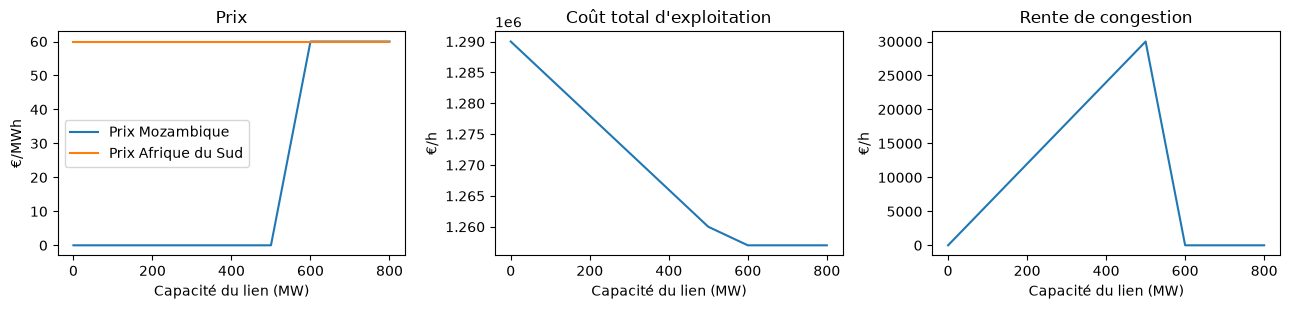

In [43]:
# TODO : balayer la capacité du lien (0, 100, ..., 800 MW) et tracer prix, coût total et rente de congestion.
### DEBUT SOLUTION
lignes = {}
# Boucle : on répète le calcul pour chaque valeur ou chaque élément
for cap in range(0, 801, 100):
    m = deux_zones(cap)
    # Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
    prix = m.buses_t.marginal_price.iloc[0]
    # Flux sur les liens (MW), compté de bus0 vers bus1 : négatif = de bus1 vers bus0
    flux = m.links_t.p0["interconnexion"].iloc[0]
    lignes[cap] = {
        "Prix Mozambique": prix["Mozambique"],
        "Prix Afrique du Sud": prix["South Africa"],
        "Flux (MW)": flux,
        "Coût total (€/h)": m.objective,
        "Rente de congestion (€/h)": abs(flux * (prix["South Africa"] - prix["Mozambique"])),
    }
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
tableau = pd.DataFrame(lignes).T.rename_axis("Capacité du lien (MW)")
display(tableau.round(1))

# Création de la figure (matplotlib)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
tableau[["Prix Mozambique", "Prix Afrique du Sud"]].plot(ax=axes[0], ylabel="€/MWh", title="Prix")
tableau["Coût total (€/h)"].plot(ax=axes[1], ylabel="€/h", title="Coût total d'exploitation")
tableau["Rente de congestion (€/h)"].plot(ax=axes[2], ylabel="€/h", title="Rente de congestion")
plt.tight_layout()
plt.show()
### FIN SOLUTION

**Questions d'observation**

1. À partir de quelle capacité les deux prix deviennent-ils égaux, et pourquoi ?
2. Comment évoluent le coût total d'exploitation et la rente de congestion quand la capacité augmente ?
3. Que concluez-vous sur la capacité d'interconnexion à construire ?

**Éléments de réponse** *(cellule de correction)*

- Tant que le lien est **saturé** (capacité < 550 MW, soit l'excédent hydraulique : 1200 − 650), le Mozambique reste à un prix nul (hydraulique bon marché inutilisée) alors que l'Afrique du Sud est à 60 : les prix sont découplés.
- À partir de **550 MW** (au-delà, la ligne n'est plus saturée et tout l'excédent est exporté), les deux prix deviennent égaux (60 €/MWh) : l'hydraulique est entièrement utilisée, c'est donc le gaz sud-africain qui fixe le prix des deux zones.
- Le **coût total diminue linéairement** avec la capacité (chaque MW exporté remplace du gaz à 60) puis devient constant : **rendements décroissants** de l'interconnexion, il est inutile de dépasser 550 MW.
- La **rente de congestion n'est pas monotone** : elle augmente avec la capacité (plus de flux × même écart de prix de 60) puis **s'effondre à zéro** quand les prix s'égalisent. Une ligne parfaitement dimensionnée n'a pas de rente de congestion.

### 1.8.c Demande flexible : retrouver une courbe de demande

En 1.5, la demande industrielle de 8000 MW est modélisée avec une utilité marginale de 70 €/MWh. On fait varier cette utilité de 0 à 120 €/MWh et on observe la **quantité consommée** : on reconstruit ainsi la courbe de demande de ce consommateur.

> **Prédisez** : pour quelles utilités la demande industrielle passe-t-elle de 0 à une consommation non nulle ? Atteint-elle les 8000 MW ?

C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")
C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")
C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not

,Consommation industrielle (MW),Prix marginal (€/MWh)
Utilité marginale (€/MWh),,
0,0.0,60.0
10,0.0,60.0
20,0.0,60.0
30,0.0,60.0
40,0.0,60.0
50,0.0,60.0
60,0.0,60.0
70,4000.0,70.0
80,4000.0,80.0


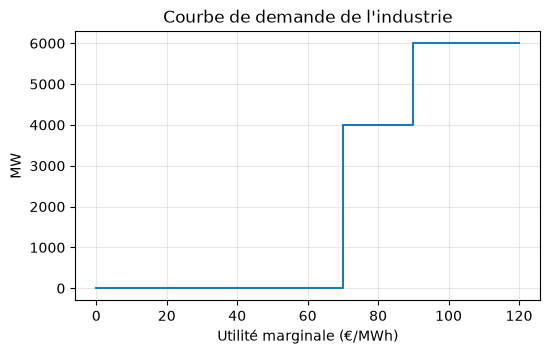

In [44]:
# TODO : pour des utilités de 0 à 120 €/MWh (pas de 10), calculer la consommation de la demande industrielle (MW)
# et le prix marginal. Tracer la quantité consommée en fonction de l'utilité.
### DEBUT SOLUTION
lignes = {}
# Boucle : on répète le calcul pour chaque valeur ou chaque élément
for u in range(0, 121, 10):
    m = reseau_afrique_du_sud(utilite_industrie=u)
    lignes[u] = {
        "Consommation industrielle (MW)": -m.generators_t.p["demande industrielle"].iloc[0],
        "Prix marginal (€/MWh)": m.buses_t.marginal_price["South Africa"].iloc[0],
    }
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
tableau = pd.DataFrame(lignes).T.rename_axis("Utilité marginale (€/MWh)")
display(tableau)

ax = tableau["Consommation industrielle (MW)"].plot(drawstyle="steps-post", figsize=(6, 3.5), ylabel="MW", title="Courbe de demande de l'industrie")
ax.grid(alpha=0.3)
plt.show()
### FIN SOLUTION

**Questions d'observation**

1. À partir de quelle utilité la consommation industrielle devient-elle non nulle ?
2. Pourquoi la consommation n'atteint-elle jamais 8 000 MW ?
3. Qui fixe le prix lorsque toute la capacité est utilisée ?

**Éléments de réponse** *(cellule de correction)*

- La consommation est **nulle** tant que l'utilité est inférieure à 60 €/MWh (le coût du gaz, marginal avec la demande de référence), passe à **4000 MW** entre 60 et 80 (il reste 4000 MW de gaz), puis à **6000 MW** au-delà de 80 (2000 MW de pétrole). Elle n'atteint **jamais 8000 MW** : la capacité installée est épuisée (48 000 MW pour 42 000 + 8000).
- On reconstruit une **courbe de demande en escalier** : un consommateur ne consomme que si sa disposition à payer dépasse le coût de la dernière unité servie. C'est exactement la logique des offres d'achat de l'exercice 2.
- Quand toute la capacité est utilisée, **c'est la demande flexible qui fixe le prix** (le prix marginal est alors égal à l'utilité marginale du dernier consommateur servi).

### 1.8.d Beaucoup d'éolien : baisse des prix et « cannibalisation »

On reprend le modèle à 4 périodes (1.6) et on augmente la capacité éolienne. On calcule le **prix moyen** et le **prix capté par l'éolien** (revenu moyen par MWh produit).

In [47]:
# TODO : pour des capacités éoliennes de 3, 10, 20, 30, 50, 80 et 120 GW, calculer le prix moyen, le profit marginal de l'éolien,
# l'énergie écrêtée (MWh) et le coût total d'exploitation.
### DEBUT SOLUTION
disponibilite = np.array([0.3, 0.6, 0.4, 0.5])
lignes = {}
# Boucle : on répète le calcul pour chaque valeur ou chaque élément
for p_vent in [3000, 10000, 20000, 30000, 50000, 80000, 120000]:
    m = reseau_afrique_du_sud(p_nom_vent=p_vent, quatre_periodes=True)
    # Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
    prix = m.buses_t.marginal_price["South Africa"]
    vent = m.generators_t.p["South Africa Wind"]
    lignes[p_vent / 1e3] = {
        "Prix moyen (€/MWh)": prix.mean(),
        "Prix capté éolien (€/MWh)": (vent * prix).sum() / vent.sum(),
        "Énergie écrêtée (MWh)": (p_vent * disponibilite - vent.values).sum(),
        "Coût d'exploitation (M€)": m.objective / 1e6,
    }
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
tableau = pd.DataFrame(lignes).T.rename_axis("Capacité éolienne (GW)")
tableau["Facteur de valeur"] = tableau["Prix capté éolien (€/MWh)"] / tableau["Prix moyen (€/MWh)"]
display(tableau.round(2))
### FIN SOLUTION

C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")
C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")
C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not

,Prix moyen (€/MWh),Prix capté éolien (€/MWh),Énergie écrêtée (MWh),Coût d'exploitation (M€),Facteur de valeur
Capacité éolienne (GW),,,,,
3.0,70.0,70.00,0.0,6.08,1.00
10.0,60.0,60.00,0.0,5.28,1.00
20.0,52.5,50.00,0.0,4.32,0.95
30.0,30.0,30.00,0.0,3.66,1.00
50.0,30.0,30.00,0.0,2.58,1.00
80.0,22.5,20.72,5000.0,1.11,0.92
120.0,7.5,6.35,46000.0,0.18,0.85


**Questions d'observation**

1. Comment évolue le prix moyen quand la capacité éolienne augmente ?
2. Le prix capté par l'éolien est-il supérieur ou inférieur au prix moyen ? Pourquoi ?
3. Que se passe-t-il pour de très grandes capacités ?

**Éléments de réponse** *(cellule de correction)*

- Le **prix moyen baisse** quand la capacité éolienne augmente : l'éolien (coût marginal nul) se place en tête de l'ordre de mérite et **déplace** les centrales plus chères (*merit-order effect*). On passe de 70 €/MWh (3 GW) à 30 €/MWh (30 GW, le charbon devient marginal) puis proche de 0.
- Le **prix capté par l'éolien est inférieur au prix moyen** pour les grandes capacités (facteur de valeur < 1) : l'éolien produit surtout quand le vent souffle, c'est-à-dire quand **tous les parcs produisent en même temps** et font baisser le prix. C'est la **cannibalisation** : plus on en installe, moins chaque MWh vaut.
- À très grande capacité, une partie de la production est **écrêtée** et les prix tombent à zéro pendant plusieurs périodes : sans stockage ni flexibilité de la demande, l'énergie excédentaire ne vaut rien.
- Le coût d'exploitation diminue mais **l'investissement n'est pas pris en compte** ici : en pratique, la baisse du prix capté décourage de nouveaux investissements (voir TD long terme).

### 1.8.e Le stockage

On reprend le modèle à 4 périodes (1.7) et on fait varier la **puissance du stockage** (de 0 à 4000 MW, avec 6 h de capacité d'énergie).

C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")
C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")
C:\Temp\ipykernel_129132\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not

,Coût d'exploitation (M€),Écart de prix max-min (€/MWh),Prix période 0,Prix période 1,Prix période 2,Prix période 3
Puissance du stockage (MW),,,,,,
0,6.08,20.0,60.0,60.0,80.0,80.0
500,6.06,20.0,60.0,60.0,80.0,80.0
1000,6.05,20.0,60.0,60.0,60.0,80.0
1500,6.04,0.0,60.0,60.0,60.0,60.0
2000,6.04,0.0,60.0,60.0,60.0,60.0
2500,6.04,0.0,60.0,60.0,60.0,60.0
3000,6.04,0.0,60.0,60.0,60.0,60.0
3500,6.04,0.0,60.0,60.0,60.0,60.0
4000,6.04,0.0,60.0,60.0,60.0,60.0


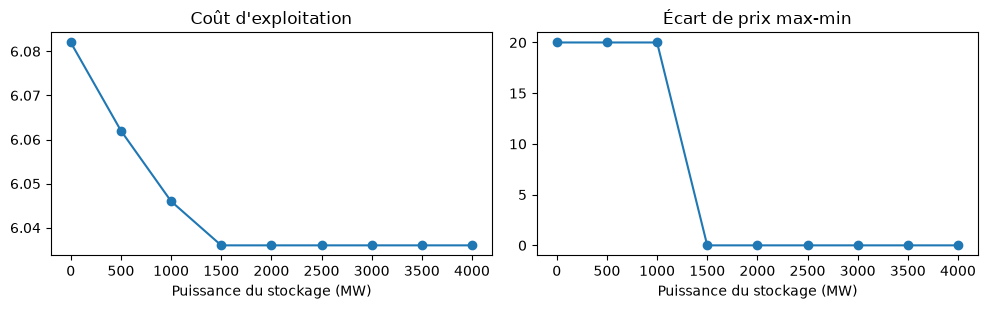

In [48]:
# TODO : pour des puissances de stockage de 0 à 4000 MW (pas de 500 MW), relever le coût d'exploitation et l'écart de prix max-min.
### DEBUT SOLUTION
lignes = {}
# Boucle : on répète le calcul pour chaque valeur ou chaque élément
for p_stockage in range(0, 4001, 500):
    m = reseau_afrique_du_sud(quatre_periodes=True, stockage=p_stockage)
    # Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
    prix = m.buses_t.marginal_price["South Africa"]
    lignes[p_stockage] = {
        "Coût d'exploitation (M€)": m.objective / 1e6,
        "Écart de prix max-min (€/MWh)": prix.max() - prix.min(),
        **{f"Prix période {t}": prix.iloc[t] for t in range(4)},
    }
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
tableau = pd.DataFrame(lignes).T.rename_axis("Puissance du stockage (MW)")
display(tableau.round(2))

# Création de la figure (matplotlib)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
tableau["Coût d'exploitation (M€)"].plot(ax=axes[0], marker="o", title="Coût d'exploitation")
tableau["Écart de prix max-min (€/MWh)"].plot(ax=axes[1], marker="o", title="Écart de prix max-min")
plt.tight_layout()
plt.show()
### FIN SOLUTION

**Questions d'observation**

1. Comment évolue le coût d'exploitation avec la puissance du stockage ?
2. Que devient l'écart de prix entre périodes, et pourquoi le gain s'annule-t-il à partir d'un certain seuil ?
3. Que vous dit cette expérience sur la valeur d'un MW de stockage supplémentaire ?

**Éléments de réponse** *(cellule de correction)*

- Le coût diminue avec la puissance du stockage mais avec des **rendements décroissants** : au-delà d'un certain seuil (ici 2000 MW), plus de stockage ne sert plus à rien car **les prix sont déjà égalisés** entre les périodes : il n'y a plus de différence de prix à exploiter (arbitrage).
- Le stockage réduit l'écart de prix **jusqu'à l'annuler** : sa valeur provient justement de cet écart. Cela illustre un phénomène général de **cannibalisation du stockage** : plus il y a de stockage, plus la valeur de chaque MW supplémentaire diminue.
- Rappel de l'énoncé de synthèse : le stockage ne réduit pas le prix à *toutes* les périodes : il l'augmente aux périodes où il charge (demande supplémentaire) et le diminue aux périodes où il décharge.

**Questions de synthèse**
- Pourquoi le prix marginal peut-il dépasser le coût moyen de production ?
- Quand une interconnexion ne permet-elle plus d’égaliser les prix ?
- Pourquoi le stockage peut-il réduire le recours à une centrale coûteuse sans nécessairement réduire le prix à toutes les périodes ?


**Éléments de réponse** *(cellule de correction)*

- **Prix marginal et coût moyen.** Le prix est celui de la centrale marginale (la plus chère appelée), alors que le coût moyen est la moyenne pondérée de toutes les centrales appelées, dont beaucoup sont moins chères. Exemple du TD (1.2) : prix de 60 EUR/MWh pour un coût moyen d'environ 30,7 EUR/MWh. La différence rémunère les coûts fixes des centrales bon marché (rentes inframarginales).
- **Quand le prix ne s'égalise plus.** Dès que la ligne est **saturée** (flux égal à sa capacité) : la zone exportatrice garde un prix bas, la zone importatrice un prix élevé. L'écart de prix est la variable duale de la limite de la ligne.
- **Stockage et prix.** Le stockage décale de l'énergie bon marché vers les périodes chères : il remplace une centrale coûteuse en période de pointe (le prix de pointe baisse), mais il ajoute de la demande en période de charge (le prix de charge ne baisse pas, il peut monter). Le prix baisse donc seulement aux périodes de décharge.

---

# Exercice 2 — Offres d’achat et de vente

## Objectifs

Modéliser un marché électrique à partir d’offres de vente et d’achat. Les quantités sont acceptées par optimisation du surplus social, sous contrainte d’équilibre entre production et consommation. On compare ensuite un marché intégré à deux zones séparées, puis reliées par une interconnexion.

Une seule période horaire est représentée : les MW et les MWh ont donc la même valeur numérique dans cet exemple.


## 2.1 Données des offres

Les offres de vente sont classées par prix croissant et les offres d’achat par disposition à payer décroissante. La quantité de chaque offre constitue une borne maximale, pas une obligation d’acceptation.

In [ ]:
# TODO : définir les offres du marché sous forme de dictionnaires {"quantite", "prix", "zone"}.
#  - offres_vente : 7 offres de vente (quantité en MW, prix en €/MWh, zone nord ou sud) ;
#  - offres_achat : 5 offres d'achat (quantité, disposition à payer, zone).
### DEBUT SOLUTION
offres_vente = {
    "quantite": [120, 100, 50, 60, 70, 60, 50],
    "prix": [0, 15, 20, 36, 60, 150, 200],
    "zone": ["nord", "sud", "nord", "nord", "sud", "nord", "sud"],
}
offres_achat = {
    "quantite": [250, 80, 20, 40, 60],
    "prix": [200, 90, 75, 65, 24],
    "zone": ["sud", "nord", "nord", "sud", "sud"],
}
### FIN SOLUTION


## 2.2 Représenter les courbes agrégées

La courbe d’offre est croissante ; la courbe de demande est décroissante. Leur croisement fournit une intuition graphique du prix de marché. L’optimisation permettra ensuite de calculer précisément les quantités acceptées.

In [ ]:
# TODO : tracer les courbes agrégées d'offre et de demande avec plt.step.
#  - abscisse : quantité cumulée (np.cumsum) ; ordonnée : prix ; les offres de vente sont triées par prix croissant,
#    celles d'achat par prix décroissant ;
#  - ajouter légendes et titres ; repérer l'intersection des deux courbes.
### DEBUT SOLUTION
# Création de la figure (matplotlib)
plt.figure(figsize=(8, 4))
plt.step(
    np.cumsum([0] + offres_vente["quantite"]),
    [offres_vente["prix"][0]] + offres_vente["prix"],
    where="post", label="Offre",
)
plt.step(
    np.cumsum([0] + offres_achat["quantite"]),
    [offres_achat["prix"][0]] + offres_achat["prix"],
    where="post", label="Demande",
)
plt.xlabel("Quantité cumulée (MW)")
plt.ylabel("Prix (€/MWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
### FIN SOLUTION


**Questions d'observation**

1. Que représentent les marches de chacune des deux courbes ?
2. Où se situe l'équilibre graphique du marché ? Quel prix et quelle quantité attendez-vous ?

**Lien avec le cours :** courbes d'offre et de demande agrégées, équilibre de marché ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

1. Chaque marche correspond à une offre : une quantité (largeur) à un prix (hauteur). L'offre est croissante (offres triées par prix croissant), la demande décroissante (disposition à payer décroissante).
2. L'équilibre se situe à l'intersection des deux courbes. Le calcul (2.3) donne un prix de 60 €/MWh : c'est le prix de la dernière offre de vente acceptée, égal à la disposition à payer marginale de l'acheteur marginal.

## 2.3 Marché intégré à une seule zone

Chaque offre de vente est représentée par un générateur de coût marginal égal à son prix d’offre. Chaque offre d’achat est représentée par un générateur de signe négatif, dont le coût marginal est l’opposé de la disposition à payer. Minimiser le coût total équivaut alors à maximiser le surplus social.

In [ ]:
# TODO : construire et résoudre le marché intégré à une seule zone.
#  - un bus "marche unique" ;
#  - une offre de vente = un Generator (p_nom = quantité, marginal_cost = prix d'offre) ;
#  - une offre d'achat = un Generator avec sign=-1 et marginal_cost = -(disposition à payer) ;
#  - résoudre avec n.optimize(solver_name="highs").
### DEBUT SOLUTION
# Réseau vide : conteneur de tous les composants (bus, générateurs, charges, liens...)
n = pypsa.Network()
# Bus = nœud du réseau : tous les composants s'y raccordent et y respectent l'équilibre offre-demande
n.add("Bus", "marche unique")

# Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
n.add(
    "Generator",
    name=[f"vente_{i}" for i in range(len(offres_vente["quantite"]))],
    bus="marche unique",
    marginal_cost=offres_vente["prix"],
    p_nom=offres_vente["quantite"],
)
n.add(
    "Generator",
    name=[f"achat_{i}" for i in range(len(offres_achat["quantite"]))],
    bus="marche unique",
    p_nom=offres_achat["quantite"],
    marginal_cost=[-p for p in offres_achat["prix"]],
    sign=-1,
)
# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n.optimize(solver_name="highs")
### FIN SOLUTION


### Lire la solution

In [ ]:
# TODO : afficher la production de chaque offre, le prix marginal du bus et la valeur de l'objectif (n.model.objective).
### DEBUT SOLUTION
# Production de chaque générateur (MW) : lignes = pas de temps, colonnes = générateurs
display(n.generators_t.p)
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
display(n.buses_t.marginal_price)
display(n.model.objective)
### FIN SOLUTION


Les offres de vente acceptées ont une production positive. Les offres d’achat acceptées ont aussi une puissance `p` **positive** (c’est la quantité achetée) : c’est l’attribut `sign=-1` qui indique que cette puissance est **consommée** dans l’équilibre du bus. Le prix marginal du bus donne le prix d’équilibre du marché intégré.

**Questions d'observation**

1. Quelles offres de vente et d'achat sont acceptées, et que valent le prix et l'objectif ?
2. Pourquoi l'objectif est-il négatif ?
3. Pourquoi une offre acceptée n'est-elle pas forcément rémunérée à son prix d'offre ?

**Lien avec le cours :** maximisation du surplus social ; un marché à prix unique est équivalent à un problème d'optimisation ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

1. Les offres de vente les moins chères et les offres d'achat les plus élevées sont acceptées ; le prix est de 60 €/MWh. L'offre au prix marginal est acceptée en partie (volume qui équilibre le marché).
2. L'objectif vaut -53 040 : on minimise (coût des ventes) - (valeur des achats) ; un objectif négatif signifie un surplus social positif de 53 040 €/h.
3. Toutes les offres acceptées reçoivent le prix de marché (60 €/MWh) : un vendeur dont le prix d'offre est inférieur perçoit une rente, un acheteur dont la disposition à payer est supérieure réalise un surplus.

## 2.4 Deux zones sans interconnexion

On affecte chaque offre à une zone. Sans interconnexion, chaque zone doit équilibrer localement les offres d’achat et de vente qui lui sont attribuées. Les prix peuvent diverger et certaines transactions mutuellement avantageuses dans le marché intégré ne sont plus possibles.

In [ ]:
# TODO : construire et résoudre le même marché avec deux zones isolées (bus "nord" et "sud", sans ligne).
#  - mêmes offres que précédemment, rattachées à leur zone ;
#  - résoudre.
### DEBUT SOLUTION
# Réseau vide : conteneur de tous les composants (bus, générateurs, charges, liens...)
n2 = pypsa.Network()
# Bus = nœud du réseau : tous les composants s'y raccordent et y respectent l'équilibre offre-demande
n2.add("Bus", "nord")
n2.add("Bus", "sud")

# Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
n2.add(
    "Generator",
    name=[f"vente_{i}" for i in range(len(offres_vente["quantite"]))],
    bus=offres_vente["zone"],
    marginal_cost=offres_vente["prix"],
    p_nom=offres_vente["quantite"],
)
n2.add(
    "Generator",
    name=[f"achat_{i}" for i in range(len(offres_achat["quantite"]))],
    bus=offres_achat["zone"],
    p_nom=offres_achat["quantite"],
    marginal_cost=[-p for p in offres_achat["prix"]],
    sign=-1,
)
# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n2.optimize(solver_name="highs")
### FIN SOLUTION


In [ ]:
# TODO : afficher les prix marginaux des deux zones et comparer les valeurs de l'objectif (marché intégré n et zones isolées n2).
### DEBUT SOLUTION
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
display(n2.buses_t.marginal_price)
display(n.objective)
display(n2.objective)
### FIN SOLUTION


**Questions d'observation**

1. Que valent les prix dans chaque zone isolée, et pourquoi sont-ils si différents ?
2. Comparez les valeurs de l'objectif : que perd-on à isoler les zones ?

**Lien avec le cours :** surplus social et rôle du couplage de marchés ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

1. Nord : 0 €/MWh (offres bon marché en excès) ; sud : 200 €/MWh (offre insuffisante, c'est la disposition à payer de l'acheteur marginal qui fixe le prix).
2. L'objectif passe de -53 040 (marché intégré) à -37 000 (zones isolées) : le surplus social baisse d'environ 30 %, car des échanges avantageux entre zones sont impossibles.

## 2.5 Ajouter une interconnexion

Une ligne de 100 MW relie le nord et le sud. Les possibilités d’échange augmentent, mais restent limitées par la capacité de transport.

In [ ]:
# TODO : ajouter une Line "interconnexion" de 100 MW entre nord et sud, résoudre à nouveau n2,
# puis afficher l'objectif et les prix marginaux.
### DEBUT SOLUTION
# Line = ligne alternative soumise aux lois de Kirchhoff (s_nom : capacité, x : réactance)
n2.add("Line", "interconnexion", bus0="nord", bus1="sud", s_nom=100)
# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n2.optimize(solver_name="highs")
display(n2.objective)
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
display(n2.buses_t.marginal_price)
### FIN SOLUTION


**Questions d'observation**

1. Que valent les prix et l'objectif avec une ligne de 100 MW ? Les prix sont-ils égaux ?
2. Quelle part de la perte de surplus la ligne permet-elle de récupérer ?
3. Pourquoi les prix restent-ils différents malgré la ligne ?

**Lien avec le cours :** valeur d'une interconnexion et congestion ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

1. L'objectif devient -52 220 ; les prix sont de 36 €/MWh au nord et 65 €/MWh au sud : ils ne sont pas égaux.
2. La ligne récupère presque toute la perte : on passe de -37 000 à -52 220, pour un maximum de -53 040 (environ 98 % du surplus du marché intégré).
3. La ligne de 100 MW est saturée : elle ne suffit pas à égaliser les prix. L'écart de prix (29 €/MWh) est la valeur d'un MW de capacité de ligne supplémentaire.

## 2.6 Pour explorer : surplus, effets redistributifs et capacité d'interconnexion

#### 2.6.a Décomposer le bien-être social

Dans le modèle, minimiser le coût total équivaut à **maximiser le surplus social**. On peut le décomposer en trois parts :

- **surplus des consommateurs** : $\sum (\text{disposition à payer} - \text{prix}) \times \text{quantité achetée}$ ;
- **surplus des producteurs** : $\sum (\text{prix} - \text{prix d'offre}) \times \text{quantité vendue}$ ;
- **rente de congestion** : flux $\times$ écart de prix entre les deux zones (lorsqu'une ligne existe).

La fonction suivante (fournie) calcule ces grandeurs. Elle suppose que les offres de vente s'appellent `vente_i` et les offres d'achat `achat_i`.

> **Convention de signe.** Pour les offres d'achat, on a utilisé `sign=-1` : la puissance `p` reste **positive** (quantité achetée) et c'est le signe qui indique que cette puissance est *consommée* dans l'équilibre du bus.

In [ ]:
def surplus(m):
    """Surplus des consommateurs (SC), des producteurs (SP), rente de congestion et bien-être social."""
    p = m.generators_t.p.iloc[0]
    prix = m.buses_t.marginal_price.iloc[0]
    g = m.generators
    prix_bus = g.bus.map(prix)
    ventes = g.index.str.startswith("vente")
    achats = g.index.str.startswith("achat")
    sp = ((prix_bus - g.marginal_cost) * p)[ventes].sum()
    sc = ((-g.marginal_cost - prix_bus) * p)[achats].sum()   # -marginal_cost = disposition à payer
    rente = 0.0
    if len(m.lines):
        ligne = m.lines.iloc[0]
        rente = abs(m.lines_t.p0.iloc[0, 0] * (prix[ligne.bus1] - prix[ligne.bus0]))
    return pd.Series({"SC": sc, "SP": sp, "Rente de congestion": rente, "Bien-être social": sc + sp + rente})

In [ ]:
# TODO : calculer la décomposition du bien-être pour le marché intégré (n), les deux zones isolées (réseau n2 construit en 2.4,
# avant l'ajout de la ligne : reconstruisez-le si besoin) et les deux zones avec la ligne de 100 MW (2.5).
# Vérifier que SC + SP + rente = -objectif.
### DEBUT SOLUTION
def marche_deux_zones(s_nom=None):
    # Réseau vide : conteneur de tous les composants (bus, générateurs, charges, liens...)
    m = pypsa.Network()
    # Bus = nœud du réseau : tous les composants s'y raccordent et y respectent l'équilibre offre-demande
    m.add("Bus", "nord")
    m.add("Bus", "sud")
    # Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
    m.add("Generator", name=[f"vente_{i}" for i in range(len(offres_vente["quantite"]))], bus=offres_vente["zone"],
          marginal_cost=offres_vente["prix"], p_nom=offres_vente["quantite"])
    m.add("Generator", name=[f"achat_{i}" for i in range(len(offres_achat["quantite"]))], bus=offres_achat["zone"],
          p_nom=offres_achat["quantite"], marginal_cost=[-p for p in offres_achat["prix"]], sign=-1)
    if s_nom is not None:
        # Line = ligne alternative soumise aux lois de Kirchhoff (s_nom : capacité, x : réactance)
        m.add("Line", "interconnexion", bus0="nord", bus1="sud", s_nom=s_nom)
    # optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
    m.optimize(solver_name="highs")
    return m

cas = {
    "Marché intégré": n,
    "Deux zones isolées": marche_deux_zones(),
    "Deux zones + ligne 100 MW": marche_deux_zones(100),
}
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
bilan = pd.DataFrame({nom: surplus(m) for nom, m in cas.items()}).T
bilan["-objectif"] = [-m.objective for m in cas.values()]
display(bilan.round(0))
### FIN SOLUTION

**Questions d'observation**

1. Vérifiez la relation SC + SP + rente = -objectif. Que représente chaque terme ?
2. Comment se répartit le surplus entre consommateurs et producteurs dans les trois cas ?

**Lien avec le cours :** surplus des consommateurs et des producteurs, rente de congestion ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

- La somme SC + SP + rente est **exactement égale à l'opposé de l'objectif** : c'est la définition du surplus social dans ce modèle.
- Le marché **intégré** (un seul prix) donne le surplus maximal. Le découpage en deux zones **sans ligne** détruit environ 30 % du surplus (certaines transactions avantageuses entre zones sont impossibles), et le prix devient très différent dans les deux zones. La ligne de 100 MW récupère la quasi-totalité de la perte.
- Notez que les prix dans les zones isolées sont extrêmes (un prix nul au nord, 200 €/MWh au sud) : **un prix peut valoir la disposition à payer du consommateur marginal** quand l'offre manque.

#### 2.6.b Faire varier la capacité de la ligne

> **Prédisez** : à partir de quelle capacité les deux prix sont-ils égaux ? Le surplus des *consommateurs* du sud augmente-t-il toujours avec la capacité ?

In [ ]:
# TODO : pour des capacités de ligne de 0, 25, 50, 100, 150, 200 et 300 MW, tracer le bien-être social, le surplus des
# consommateurs, celui des producteurs, la rente de congestion et les prix des deux zones.
### DEBUT SOLUTION
lignes = {}
# Boucle : on répète le calcul pour chaque valeur ou chaque élément
for cap in [0, 25, 50, 100, 150, 200, 300]:
    m = marche_deux_zones(cap)
    # Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
    prix = m.buses_t.marginal_price.iloc[0]
    lignes[cap] = {**surplus(m).to_dict(), "Prix nord": prix["nord"], "Prix sud": prix["sud"]}
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
tableau = pd.DataFrame(lignes).T.rename_axis("Capacité de ligne (MW)")
display(tableau.round(1))

# Création de la figure (matplotlib)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
tableau[["SC", "SP", "Rente de congestion", "Bien-être social"]].plot(ax=axes[0], marker="o", title="Surplus")
tableau[["Prix nord", "Prix sud"]].plot(ax=axes[1], marker="o", title="Prix (€/MWh)")
plt.tight_layout()
plt.show()
### FIN SOLUTION

**Questions d'observation**

1. Comment évolue le bien-être social avec la capacité de la ligne ?
2. Le surplus des consommateurs augmente-t-il toujours avec la capacité ? Qui gagne, qui perd ?
3. Comment évolue la rente de congestion ?

**Lien avec le cours :** bien-être social, effets redistributifs et incitations à investir ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

- Le bien-être social **augmente avec la capacité** puis **plafonne** à la valeur du marché intégré dès que la ligne n'est plus saturée (150 MW ici) : les prix s'égalisent à 60 €/MWh.
- Le surplus n'est pas réparti de façon uniforme : **une petite ligne (25-50 MW) fait baisser le surplus des consommateurs** (les consommateurs du nord paient plus cher, car la ligne leur fait exporter de l'électricité bon marché) mais augmente celui des producteurs et crée une rente de congestion. L'interconnexion augmente le surplus total mais crée des **gagnants et des perdants** : c'est un enjeu politique réel des couplages de marchés.
- La rente de congestion est maximale pour une capacité intermédiaire puis tombe à zéro : un opérateur de réseau qui maximiserait cette rente aurait intérêt à **limiter** la capacité (conflit d'intérêts), alors que le bien-être social serait maximal avec une ligne plus grande.

#### 2.6.c Effet d'une offre à prix nul (énergies renouvelables fatales)

On ajoute au marché intégré une offre de vente de **150 MW à 0 €/MWh** (parc éolien/solaire subventionné ou production fatale). On compare le prix, le surplus des consommateurs et celui des producteurs.

In [ ]:
# TODO : ajouter l'offre au marché intégré (réseau n copié), le résoudre, puis comparer prix et surplus avec la situation de départ.
### DEBUT SOLUTION
# Copie du réseau (l'original reste intact, ce qui permet de comparer des variantes)
n_enr = copier_reseau(n)
# Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
n_enr.add("Generator", "vente_enr", bus="marche unique", p_nom=150, marginal_cost=0)
# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n_enr.optimize(solver_name="highs")

# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
comparaison = pd.DataFrame({"sans offre à 0": surplus(n), "avec offre à 0": surplus(n_enr)})
# Modification d'un paramètre : on écrit dans le tableau avec .loc[nom du composant, attribut]
comparaison.loc["Prix (€/MWh)"] = [n.buses_t.marginal_price.iloc[0, 0], n_enr.buses_t.marginal_price.iloc[0, 0]]
display(comparaison.round(1))
### FIN SOLUTION

**Questions d'observation**

1. Comment le prix, le surplus des consommateurs et celui des producteurs évoluent-ils avec l'offre à prix nul ?
2. Le bien-être total augmente-t-il ? Pour qui l'effet est-il négatif ?

**Lien avec le cours :** effet d'ordre de mérite et rentabilité des centrales conventionnelles ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

Le prix **chute** (de 60 à 24 €/MWh) : les offres de vente les plus chères sont évincées. Les **consommateurs gagnent** beaucoup, les **producteurs conventionnels perdent** (ils vendent moins et moins cher) alors que le bien-être total augmente. C'est le **merit-order effect** : l'arrivée d'une capacité à coût marginal quasi nul tire les prix vers le bas, ce qui pose ensuite la question de la rentabilité des centrales conventionnelles (voir 1.8.d et le TD long terme).

**Questions de synthèse (suite)**
- Pourquoi le « bien-être social » est-il identique à l'opposé de la fonction objectif ?
- Qui gagne et qui perd lors de la mise en place d'une interconnexion ? Qu'est-ce que cela implique pour la décision de la construire ?

**Éléments de réponse** *(cellule de correction)*

- **Bien-être social et objectif.** Le modèle minimise (coût des offres de vente acceptées) - (valeur des offres d'achat acceptées) : l'opposé de l'objectif est donc la somme des surplus (consommateurs, producteurs, rente de congestion) : le bien-être social.
- **Gagnants et perdants.** L'interconnexion augmente le surplus total, mais redistribue : les consommateurs de la zone importatrice et les producteurs de la zone exportatrice gagnent, les producteurs de la zone importatrice et les consommateurs de la zone exportatrice perdent (prix qui monte pour eux). La décision de construire ne dépend donc pas seulement du gain total, mais aussi de sa répartition et de qui finance la ligne (rente de congestion).

**Questions de synthèse**
- Pourquoi le découpage en zones peut-il réduire le surplus social ?
- Dans quel cas les prix des deux zones sont-ils égaux ?
- Comment interpréter une ligne saturée et un écart de prix persistant entre les deux zones ?


**Éléments de réponse** *(cellule de correction)*

- **Découpage en zones.** Il empêche des échanges avantageux (un acheteur disposé à payer plus cher qu'un vendeur d'une autre zone) : ces transactions manquantes réduisent le surplus social.
- **Prix égaux.** Quand la capacité de ligne est suffisante pour que le flux ne soit pas saturé : les deux prix s'égalisent (marché intégré).
- **Ligne saturée et écart persistant.** L'écart de prix est la valeur d'un MW de capacité en plus ; la rente de congestion (flux x écart de prix) mesure ce que rapporte la ligne. Un écart persistant signale un besoin de renforcement du réseau.

---

# Exercice 3 — Réseau de transport : dispatch optimal puis flux de puissance (SciGRID)

## Objectifs

Jusqu'ici, un « marché » était un seul nœud ou quelques zones reliées par des interconnexions simples. Ici, on étudie un **vrai réseau maillé** : le réseau de transport allemand (environ 600 nœuds, 850 lignes), avec ses centrales, son stockage par pompage et sa charge. Vous allez :

1. optimiser le dispatch avec un **flux de puissance optimal linéaire** (LOPF) ;
2. interpréter les **prix nodaux** (LMP, *locational marginal prices*) et la **congestion** ;
3. mesurer l'**écrêtement** de l'éolien dû au réseau ;
4. comparer le résultat avec un **flux de puissance non linéaire** (AC, Newton-Raphson) : pertes, charge des lignes, puissance réactive ;
5. **expérimenter** : marge de sécurité N-1, « plaque de cuivre », doublement de l'éolien, cas infaisable.

Cet exercice reprend l'exemple `scigrid-lopf-then-pf` de la documentation PyPSA.

## Données

- **Réseau :** basé sur [SciGRID](https://openenergyplatform.org/factsheets/models/22/), lui-même issu d'OpenStreetMap.
- **Charge :** répartie proportionnellement au PIB et à la population des régions NUTS3 ; série temporelle horaire ENTSO-E, multipliée par 1,12.
- **Centrales conventionnelles :** liste de la BNetzA (agence fédérale allemande des réseaux).
- **Éolien et solaire :** capacités installées fin 2014 (EEG Stammdaten, EnergyMap) ; séries temporelles générées avec l'outil REatlas.
- **Période :** la journée du **1er janvier 2011**, pas horaire (24 instants).

> **Limites.** Ces données ne sont plus mises à jour et servent uniquement à illustrer les capacités de PyPSA ; elles ne conviennent pas à la recherche (voir [PyPSA-Eur](https://github.com/PyPSA/pypsa-eur) pour un modèle maintenu). Parmi les approximations : transformateurs 220/380 kV et connexions manquantes dans OSM, congestions inattendues dans certaines régions, frontières et pays voisins non représentés, centrales hydrauliques approximatives, coûts marginaux illustratifs, pas de coûts de démarrage ni de rampes, un seul jour non représentatif.

## 3.1 Charger et explorer les données

Le réseau est fourni par PyPSA. On commence par visualiser où se trouvent la **charge** et les **moyens de production**.

In [ ]:
import cartopy.crs as ccrs

n_sg = pypsa.examples.scigrid_de()
print(n_sg)

In [ ]:
fig, ax = plt.subplots(1, 1, subplot_kw={"projection": ccrs.EqualEarth()})

repartition_charge = n_sg.loads_t.p_set.loc[n_sg.snapshots[0]].groupby(n_sg.loads.bus).sum()
n_sg.plot(bus_size=repartition_charge / 30000, ax=ax, title="Répartition de la charge")
plt.show()

In [ ]:
display(n_sg.generators.groupby("carrier")["p_nom"].sum().round(1).rename("Capacité (MW)"))
display(n_sg.storage_units.groupby("carrier")["p_nom"].sum().round(1).rename("Capacité (MW)"))
display(n_sg.generators.groupby("carrier")["marginal_cost"].mean().round(1).rename("Coût marginal moyen (€/MWh)"))

In [ ]:
techs = ["Gas", "Brown Coal", "Hard Coal", "Wind Offshore", "Wind Onshore", "Solar"]
n_cols = 3
n_rows = -(-len(techs) // n_cols)   # division entière par excès

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, subplot_kw={"projection": ccrs.EqualEarth()})
fig.set_size_inches(6 * n_cols, 6 * n_rows)

for ax, tech in zip(axes.flat, techs):
    gens = n_sg.generators[n_sg.generators.carrier == tech]
    repartition = gens.groupby("bus")["p_nom"].sum().reindex(n_sg.buses.index, fill_value=0)
    n_sg.plot(ax=ax, bus_size=repartition / 20000)
    ax.set_title(tech)
fig.tight_layout()
plt.show()

**Questions**
1. Où se situent les principaux centres de consommation ? Où sont les gisements de production éolienne (terrestre et en mer), solaire, charbon (lignite et houille) ?
2. Repérez l'écart géographique entre production à bas coût et consommation. Quelle conséquence anticipez-vous pour le réseau ?
3. Classez les technologies par coût marginal moyen : cet ordre est-il cohérent avec ce que vous avez vu à l'exercice 1 ?

**Lien avec le cours :** localisation de la production et de la charge, besoin de transport ([Rappel de cours](#Rappel-de-cours), contrainte « bilan nodal » et « limites de transmission »).

**Éléments de réponse** *(cellule de correction)*

1. La **charge** est concentrée dans les zones densément peuplées et industrielles (Ruhr/Rhénanie, Rhin-Main, Stuttgart, Munich, Berlin, Hambourg). L'**éolien** est surtout dans le nord (côtes, mer du Nord et mer Baltique pour l'offshore), le **solaire** surtout dans le sud, le **lignite** dans les bassins de Rhénanie (ouest) et de Lusace (est), la **houille** et le **gaz** sont plus diffus, près des centres de consommation et des ports.
2. Une grande partie de la production à très bas coût (éolien du nord, lignite) est **éloignée** des principaux centres de consommation (ouest et sud) : il faudra transporter de l'énergie du nord vers le sud, ce qui peut saturer les lignes nord-sud.
3. L'ordre croissant des coûts marginaux (renouvelables et nucléaire/fil de l'eau très bas, puis lignite, houille, gaz) est celui de l'**ordre de mérite** vu à l'exercice 1.

## 3.2 Optimiser le dispatch : le LOPF

### Principe

Le LOPF (*linear optimal power flow*) minimise le coût de production sous contraintes :
- équilibre offre-demande à chaque **nœud** ;
- limites des centrales ;
- lois de Kirchhoff, approchées par les **équations de flux continu (DC)** : le flux sur une ligne est proportionnel à la différence d'angle de tension entre ses extrémités (le courant se répartit **selon l'impédance des lignes**, on ne peut pas choisir librement le chemin, contrairement à un lien `Link`) ;
- capacité des lignes : $|f_\ell| \le s_{\text{nom},\ell} \times s_{\text{max pu},\ell}$.

### La marge N-1

Pour représenter approximativement la **sécurité N-1** (le réseau doit supporter la perte d'une ligne) et laisser de la place pour la puissance réactive, on interdit de charger les lignes au-delà de **70 %** de leur capacité thermique (`s_max_pu = 0.7`). Quelques lignes sont infaisables sans petites extensions : on augmente légèrement leur capacité.

### Horizon glissant

On optimise la journée **4 pas de temps à la fois** (`optimize_with_rolling_horizon`) : cela rend les calculs plus rapides, et c'est ainsi que fonctionne une exploitation réelle (on ne connaît pas toute la journée à l'avance). L'état du stockage est transmis d'une fenêtre à la suivante (voir l'exercice 4 pour les conséquences de cette miopie).

> Ce calcul prend de l'ordre de 30 secondes.

In [ ]:
facteur_contingence = 0.7
n_sg.lines.s_max_pu = facteur_contingence
n_sg.lines.loc[["316", "527", "602"], "s_nom"] = 1715      # petites extensions pour éviter l'infaisabilité

n_vierge = n_sg.copy()    # réseau non optimisé, conservé pour les expériences de la section 3.7

In [ ]:
# TODO : lancer l'optimisation à horizon glissant (4 pas de temps, sans recouvrement).
### DEBUT SOLUTION
# Horizon glissant : on optimise fenêtre par fenêtre, l'état du stockage passe d'une fenêtre à la suivante
n_sg.optimize.optimize_with_rolling_horizon(horizon=4, overlap=0, solver_name="highs")
### FIN SOLUTION

### Toujours vérifier que le résultat est cohérent

L'optimisation à horizon glissant **n'interrompt pas** le calcul si une fenêtre est infaisable : elle peut renvoyer des productions nulles sans erreur visible. Avant d'analyser quoi que ce soit, on vérifie que **production + déstockage = charge** à chaque instant (fonction fournie).

In [ ]:
def verifier_bilan(m, tolerance=1.0):
    """Vérifie que production + déstockage = charge à chaque pas de temps (en MW). Renvoie True si tout va bien."""
    production = m.generators_t.p.sum(axis=1) + m.storage_units_t.p.sum(axis=1)
    ecart = (production - m.loads_t.p_set.sum(axis=1)).abs()
    if (ecart > tolerance).any():
        print(f"Bilan non respecté à {int((ecart > tolerance).sum())} pas de temps sur {len(ecart)} : "
              f"le calcul a probablement été infaisable. Résultats inutilisables.")
        return False
    print("Bilan offre-demande respecté à chaque pas de temps.")
    return True

In [ ]:
verifier_bilan(n_sg)

**Questions d'observation**

1. Que vérifie la fonction verifier_bilan et pourquoi est-ce nécessaire avant d'analyser les résultats ?
2. Que signifierait un déséquilibre à certains pas de temps ?

**Lien avec le cours :** contrainte d'équilibre offre-demande à chaque nœud et à chaque pas de temps ([Rappel de cours](#Rappel-de-cours), « bilan nodal »).

**Éléments de réponse** *(cellule de correction)*

1. Elle contrôle l'identité production + déstockage = charge à chaque pas de temps. Un solveur peut renvoyer une solution vide ou inexploitable sans erreur visible : il faut vérifier une identité simple avant toute interprétation.
2. Un déséquilibre signale un problème infaisable ou une résolution inachevée : les résultats ne peuvent pas être interprétés.

## 3.3 Le dispatch par technologie et le stockage

On trace la production horaire cumulée par technologie (les technologies de moins de 1,7 GW de pic sont omises pour la lisibilité), puis le comportement du **stockage par pompage**.

In [ ]:
# TODO : calculer la production par technologie (MW), retirer les petites technologies et tracer le dispatch en aires empilées (GW).
### DEBUT SOLUTION
# Regroupement (groupby) : on agrège par technologie, par pays ou par période
p_par_carrier = n_sg.generators_t.p.T.groupby(n_sg.generators.carrier).sum().T
petites = p_par_carrier.max()[p_par_carrier.max() < 1700].index
p_par_carrier = p_par_carrier.drop(columns=petites)

couleurs = {
    "Brown Coal": "brown", "Hard Coal": "k", "Nuclear": "r", "Run of River": "green",
    "Wind Onshore": "blue", "Solar": "yellow", "Wind Offshore": "cyan", "Waste": "orange", "Gas": "orange",
}
ordre = ["Nuclear", "Run of River", "Brown Coal", "Hard Coal", "Gas", "Wind Offshore", "Wind Onshore", "Solar"]
p_par_carrier = p_par_carrier[[c for c in ordre if c in p_par_carrier.columns]]

# Création de la figure (matplotlib)
fig, ax = plt.subplots(figsize=(9, 4))
p_par_carrier.div(1e3).plot(kind="area", ax=ax, lw=0, color=[couleurs[c] for c in p_par_carrier.columns], alpha=0.7)
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, 1.02, 1, 0.2), frameon=False)
ax.set_ylabel("GW")
ax.set_xlabel("")
plt.show()
### FIN SOLUTION

In [ ]:
# TODO : tracer sur un même graphique la puissance totale du stockage par pompage (MW, positive = turbinage)
# et l'énergie stockée (MWh) au cours du temps (somme sur toutes les unités de stockage).
### DEBUT SOLUTION
# Création de la figure (matplotlib)
fig, ax = plt.subplots(figsize=(9, 3.5))
# Puissance du stockage (MW) : positive = décharge, négative = charge
n_sg.storage_units_t.p.sum(axis=1).plot(label="Puissance du pompage-turbinage (MW, >0 = turbinage)", ax=ax)
# État de charge du stockage (MWh)
n_sg.storage_units_t.state_of_charge.sum(axis=1).plot(label="Énergie stockée (MWh)", ax=ax)
ax.axhline(0, color="k", lw=0.5, ls="--")
ax.legend()
ax.set_xlabel("")
plt.show()
### FIN SOLUTION

**Questions**
1. Quelles technologies tournent quasiment à puissance constante (« base ») ? Lesquelles s'ajustent (« suiveuses ») ? Reliez-le à leur coût marginal.
2. À quels moments le stockage par pompage charge-t-il, et décharge-t-il ? Pourquoi ?
3. L'énergie stockée en fin de journée est-elle égale à celle du début ? Que cela change-t-il pour l'interprétation ?

**Lien avec le cours :** ordre de mérite, production de base et de suivi de charge, arbitrage temporel du stockage ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

1. Le **nucléaire**, le **fil de l'eau** et le **lignite** (coût marginal bas) fournissent la base ; la **houille** et le **gaz** (coût plus élevé) suivent la charge ; l'éolien et le solaire suivent la **disponibilité de la ressource**, pas la charge.
2. Le pompage charge la **nuit**, quand la demande et donc les prix sont bas, et turbine pendant les pointes du matin/soir : c'est de l'**arbitrage** temporel, comme à l'exercice 1.7.
3. Sur une journée avec horizon glissant, l'état du stockage n'est pas forcé à revenir à son niveau initial. Un stockage qui se vide à la fin d'une fenêtre est un effet de **myopie** de l'horizon court : le modèle n'a aucune raison de conserver de l'énergie pour la suite (voir l'exercice 4 sur la valeur de l'eau).

## 3.4 Charge des lignes et prix nodaux (LMP)

On s'intéresse à un instant précis, 04:00 (`n_sg.snapshots[4]`, le 5e pas de temps). Vous pouvez changer cet instant pour comparer (par exemple la pointe du soir, `n_sg.snapshots[18]`).

In [ ]:
instant = n_sg.snapshots[4]
print("Instant analysé :", instant)

charge_lignes = (n_sg.lines_t.p0.loc[instant] / n_sg.lines.s_nom).abs()
display(charge_lignes.describe().round(2))

fig, ax = plt.subplots(subplot_kw={"projection": ccrs.EqualEarth()})
n_sg.plot(ax=ax, line_color=charge_lignes, line_cmap="viridis", title="Charge des lignes (flux / capacité)", bus_size=1e-3)
plt.show()

### Prix nodaux (LMP)

Dans un modèle de réseau, chaque **nœud** a son propre prix marginal : c'est la variable duale de l'équilibre du nœud, soit le coût d'1 MWh supplémentaire *à cet endroit*. En l'absence de congestion, tous les prix sont égaux (sans pertes) ; la **congestion** les différencie.

In [ ]:
# TODO : décrire la distribution des prix nodaux à l'instant choisi et les représenter sur une carte.
### DEBUT SOLUTION
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
prix_nodaux = n_sg.buses_t.marginal_price.loc[instant]
display(prix_nodaux.describe().round(1))

# Création de la figure (matplotlib)
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.PlateCarree()})
plt.hexbin(n_sg.buses.x, n_sg.buses.y, gridsize=20, C=prix_nodaux, cmap="viridis", zorder=-1)
n_sg.plot(ax=ax, line_width=1, bus_size=0)
plt.colorbar(location="right").set_label("Prix nodal (€/MWh)")
plt.show()
### FIN SOLUTION

**Questions**
1. Les prix sont-ils les mêmes partout ? Que vous dit la dispersion des prix sur l'état du réseau ?
2. Quelles régions ont des prix bas, quelles régions des prix élevés ? Rapprochez-le de la carte de production (3.1).
3. Combien de lignes sont **saturées** (charge égale à la limite 70 %) à cet instant ?

**Lien avec le cours :** prix nodaux (LMP) et congestion : variables duales du bilan nodal et des limites de transmission ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

1. Les prix **diffèrent fortement** entre nœuds : sans congestion ils seraient tous égaux à celui de la dernière centrale appelée. La dispersion est le signe que le réseau **limite** les transferts : l'électricité bon marché ne peut pas atteindre tous les consommateurs.
2. Les prix sont **bas** dans les zones d'excédent de production bon marché (typiquement le nord, riche en éolien et lignite) et **élevés** dans les zones déficitaires (centres de consommation du sud et de l'ouest), qui doivent faire appel à des centrales plus chères *locales*. L'écart de prix entre deux nœuds d'une ligne saturée mesure la valeur d'1 MW de capacité de transport supplémentaire.
3. Comptez-les avec `(charge_lignes >= 0.7 - 1e-6).sum()` : ce sont les lignes qui contraignent le dispatch.

## 3.5 Écrêtement de l'éolien

En comparant la production **disponible** (`p_max_pu × p_nom`) à la production **dispatchée**, on mesure la part de l'éolien terrestre qui est écrêtée. Rappelez-vous qu'aucun coût n'est associé à la perte de cette énergie : si le modèle l'écrête, c'est que **c'est optimal** sous les contraintes.

In [ ]:
# TODO : calculer, pour l'éolien terrestre, la production disponible, dispatchée et écrêtée (MW) à chaque instant, puis la tracer.
### DEBUT SOLUTION
carrier = "Wind Onshore"
eolien = n_sg.generators.index[n_sg.generators.carrier == carrier]
capacite = n_sg.generators.loc[eolien, "p_nom"].sum()
disponible = (n_sg.generators_t.p_max_pu[eolien] * n_sg.generators.loc[eolien, "p_nom"]).sum(axis=1)
dispatche = n_sg.generators_t.p[eolien].sum(axis=1)
ecrete = (disponible - dispatche).clip(lower=0)

# Création de la figure (matplotlib)
fig, ax = plt.subplots(figsize=(9, 4))
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
pd.DataFrame({"dispatché": dispatche, "écrêté": ecrete}).plot(kind="area", ax=ax, lw=0)
disponible.plot(ax=ax, color="k", label="disponible")
ax.axhline(capacite, color="grey", ls=":", label="capacité installée")
ax.set_ylabel("MW")
ax.set_xlabel("")
ax.set_ylim(0, 40000)
ax.legend()
plt.show()
print(f"Énergie écrêtée sur la journée : {ecrete.sum() / 1e3:.1f} GWh ({100 * ecrete.sum() / disponible.sum():.1f} % du disponible)")
### FIN SOLUTION

**Questions d'observation**

1. À quels moments l'éolien est-il écrêté et dans quelle proportion ?
2. Cet écrêtement est-il dû à un excès global de production ou au réseau ? Comment le vérifier ?

**Lien avec le cours :** congestion, redispatch et contraintes de réseau ([Rappel de cours](#Rappel-de-cours), « limites de transmission »).

**Éléments de réponse** *(cellule de correction)*

L'écrêtement observé n'est **pas** dû à un excédent global de production (les centrales conventionnelles pourraient réduire leur production, il n'y a pas de minimum technique) : il est dû au **réseau** (congestion nord-sud). Vous le vérifierez en 3.7.c : sans contrainte de réseau, l'écrêtement disparaît. C'est un phénomène réel : en Allemagne, une grande partie de l'éolien écrêté (*redispatch*) est située dans le nord.

## 3.6 Du LOPF au flux de puissance non linéaire

Le LOPF repose sur des approximations : **flux continu (DC)**, pas de pertes, pas de puissance réactive, tensions supposées égales à 1 pu. Pour tester la qualité de ce résultat, on fixe la production issue de l'optimisation et on résout les **équations complètes du flux de puissance alternatif** (méthode de Newton-Raphson) : tensions, angles, puissances réactives, pertes.

On travaille sur une **copie** `n_pf` (le flux de puissance modifie légèrement la production, car un générateur « balancier » absorbe les pertes). On fixe d'abord les consignes de production de l'optimisation. On ne connaît pas les consignes de puissance réactive : on déclare quasiment tous les générateurs « PV » (puissance active et module de tension imposés) et on en laisse quelques-uns « PQ » pour éviter une matrice jacobienne singulière.

In [ ]:
flux_lopf = n_sg.lines_t.p0.copy()     # on conserve les flux du LOPF pour la comparaison

n_pf = copier_reseau(n_sg)             # le flux de puissance modifie légèrement la production : on travaille sur une copie
n_pf.optimize.fix_optimal_dispatch()

n_pf.generators.control = "PV"
f = n_pf.generators[n_pf.generators.bus == "492"]
n_pf.generators.loc[f.index, "control"] = "PQ"

info = n_pf.pf()
print("Des pas de temps n'ont pas convergé :", bool((~info.converged).any().any()))

### Comparaison LOPF / flux de puissance AC

On compare (i) la **charge des lignes**, (ii) les **flux** ligne par ligne, (iii) les **pertes**, (iv) les **écarts d'angle** et la **puissance réactive**.

In [ ]:
# TODO : à l'instant choisi, (1) comparer les statistiques de charge des lignes LOPF / AC ; (2) tracer les flux AC en fonction des flux LOPF ;
# (3) calculer les pertes (somme des p0 + p1 sur lignes et transformateurs) en MW et en % de la charge.
### DEBUT SOLUTION
charge_ac = (n_pf.lines_t.p0.loc[instant] / n_pf.lines.s_nom).abs()
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
display(pd.DataFrame({"LOPF": charge_lignes.describe(), "Flux AC": charge_ac.describe()}).round(2))

# Création de la figure (matplotlib)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(flux_lopf.loc[instant], n_pf.lines_t.p0.loc[instant], s=6, alpha=0.6)
lim = n_pf.lines_t.p0.loc[instant].abs().max()
ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
ax.set_xlabel("Flux LOPF (MW)")
ax.set_ylabel("Flux AC (MW)")
plt.show()

pertes = (n_pf.lines_t.p0 + n_pf.lines_t.p1).sum(axis=1) + (n_pf.transformers_t.p0 + n_pf.transformers_t.p1).sum(axis=1)
charge_totale = n_sg.loads_t.p_set.sum(axis=1)
print(f"Pertes à {instant} : {pertes.loc[instant]:.0f} MW, soit {100 * pertes.loc[instant] / charge_totale.loc[instant]:.1f} % de la charge")
print("Lignes chargées au-delà de 70 % en AC :", int((charge_ac > 0.7 + 1e-6).sum()), "| au-delà de 100 % :", int((charge_ac > 1).sum()))
### FIN SOLUTION

In [ ]:
# TODO : (1) calculer l'écart d'angle de tension (en degrés) aux bornes de chaque ligne à l'instant choisi et en donner
# les statistiques ; (2) tracer sur une carte la puissance réactive injectée à chaque nœud (rouge = positive, bleu = négative).
### DEBUT SOLUTION
# Écarts d'angle de tension aux bornes des lignes (en degrés)
angle = n_pf.buses_t.v_ang.loc[instant]
ecart_angle = (angle[n_pf.lines.bus0].values - angle[n_pf.lines.bus1].values) * 180 / np.pi
display(pd.Series(ecart_angle).describe().round(2).rename("Écart d'angle (°)"))

# Puissance réactive injectée
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.EqualEarth()})
q = n_pf.buses_t.q.loc[instant]
n_pf.plot(bus_size=q.abs() / 1e4, ax=ax, bus_color=q.map(lambda x: "b" if x < 0 else "r"),
          title="Puissance réactive injectée\n(rouge = positive, bleu = négative)")
plt.show()
### FIN SOLUTION

**Questions**
1. Le LOPF donne-t-il une bonne image des flux ? Que valent la corrélation et la dispersion des points autour de la droite $y=x$ ?
2. Pourquoi des lignes dépassent-elles 70 % en AC ? Pourquoi aucune ne dépasse-t-elle 100 % ?
3. Les pertes sont-elles négligeables ? Où sont-elles « prises » dans le LOPF ?
4. L'approximation DC suppose de petits écarts d'angle : est-ce vérifié ?

**Lien avec le cours :** approximation en flux continu (DC) des lois de Kirchhoff, pertes et puissance réactive ([Rappel de cours](#Rappel-de-cours), contraintes « KVL » et « KCL »).

**Éléments de réponse** *(cellule de correction)*

*Ordres de grandeur obtenus avec PyPSA 1.4 et HiGHS ; vos valeurs peuvent différer légèrement selon la version du jeu de données.*

1. Les flux AC sont **très proches** des flux LOPF (corrélation > 0,99) : l'approximation DC est bonne pour représenter la **répartition des flux actifs**.
2. La limite de 70 % est imposée au LOPF, mais le flux AC contient en plus de la puissance réactive et des pertes : quelques lignes dépassent donc légèrement 70 % (charge maximale proche de 85 %). **Aucune ne dépasse 100 %** : c'est justement le rôle de la marge, qui fournit une réserve pour ce que le modèle DC ne voit pas.
3. Les pertes sont de l'ordre de **2 % de la charge** (environ 1 GW à 04:00). Le LOPF les ignore ; en AC, elles sont fournies par le générateur « balancier » (*slack*), ce qui rompt légèrement l'équilibre calculé par le LOPF. Elles sont faibles mais non négligeables.
4. Les écarts d'angle sont de quelques degrés pour la plupart des lignes (quelques lignes dépassent 10°) : l'hypothèse de petits angles est globalement vérifiée.

## 3.7 Pour explorer : sécurité, congestion et éolien

Les expériences suivantes relancent le LOPF (30 secondes chacune) sur des **variantes** du réseau non optimisé `n_vierge`. Les fonctions suivantes (fournies) lancent une variante et résument les résultats avec cinq indicateurs :

- **coût d'exploitation** de la journée (M€) ;
- **prix nodal moyen** (€/MWh) ;
- **dispersion des prix** : écart moyen entre le prix le plus haut et le plus bas des nœuds ;
- **éolien terrestre écrêté** (GWh) ;
- **nombre de lignes saturées** à au moins un instant.

In [ ]:
def simuler(facteur_contingence=0.7, plaque_de_cuivre=False, facteur_vent=1.0, horizon=4):
    """Résout le LOPF sur une variante du réseau.

    facteur_contingence : part de la capacité thermique utilisable (s_max_pu).
    plaque_de_cuivre : si True, aucune contrainte de réseau (lignes et transformateurs surdimensionnés).
    facteur_vent : multiplicateur de la capacité éolienne terrestre installée.
    """
    m = copier_reseau(n_vierge)
    m.lines.s_max_pu = facteur_contingence
    if plaque_de_cuivre:
        m.lines.s_max_pu = 1.0
        m.lines.s_nom = 1e6
        m.transformers.s_nom = 1e6
    m.generators.loc[m.generators.carrier == "Wind Onshore", "p_nom"] *= facteur_vent
    m.optimize.optimize_with_rolling_horizon(horizon=horizon, overlap=0, solver_name="highs")
    return m


def indicateurs(m):
    poids = m.snapshot_weightings.generators
    cout = m.generators_t.p.mul(m.generators.marginal_cost, axis=1).mul(poids, axis=0).sum().sum()
    prix = m.buses_t.marginal_price
    eolien = m.generators.index[m.generators.carrier == "Wind Onshore"]
    disponible = (m.generators_t.p_max_pu[eolien] * m.generators.loc[eolien, "p_nom"]).sum(axis=1)
    ecrete = (disponible - m.generators_t.p[eolien].sum(axis=1)).clip(lower=0).sum()
    limite = m.lines.s_nom * m.lines.s_max_pu
    saturees = ((m.lines_t.p0.abs().max() / limite) > 0.999).sum()
    return pd.Series({
        "Coût d'exploitation (M€)": cout / 1e6,
        "Prix nodal moyen (€/MWh)": prix.mean().mean(),
        "Dispersion des prix (€/MWh)": (prix.max(axis=1) - prix.min(axis=1)).mean(),
        "Éolien écrêté (GWh)": ecrete / 1e3,
        "Lignes saturées": saturees,
    })

### 3.7.a Un piège : une marge de sécurité trop sévère

> **Prédisez** : si l'on impose `facteur_contingence = 0.6` (au lieu de 0.7), le coût d'exploitation va-t-il augmenter ou diminuer ?

In [ ]:
# TODO : simuler avec un facteur de contingence de 0,6, vérifier le bilan, puis comparer les indicateurs avec la référence (0,7).
### DEBUT SOLUTION
m_piege = simuler(facteur_contingence=0.6)
verifier_bilan(m_piege)
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
display(pd.DataFrame({"contingence 0,7 (référence)": indicateurs(n_sg), "contingence 0,6": indicateurs(m_piege)}).round(2))
### FIN SOLUTION

**Questions d'observation**

1. Le coût obtenu avec une marge de 60 % est-il plausible ? Que dit verifier_bilan ?
2. Pourquoi un coût plus faible avec une contrainte plus sévère est-il un signal d'alarme ?

**Lien avec le cours :** faisabilité d'un problème d'optimisation et monotonie de la valeur optimale vis-à-vis des contraintes ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

Le coût d'exploitation **baisse** apparemment avec une marge plus sévère, ce qui est absurde : une contrainte plus restrictive ne peut jamais réduire le coût optimal. Le signal d'alarme est `verifier_bilan` : pour plusieurs heures du soir, la production est **nulle** alors que la charge ne l'est pas. Le problème est devenu **infaisable** : aucun dispatch ne respecte à la fois la demande et la limite de 60 % sur toutes les lignes. L'optimisation à horizon glissant ne s'arrête pas et laisse des zéros, que l'on interpréterait à tort comme un coût plus faible.

**Leçon :** un résultat d'optimisation n'est exploitable qu'après avoir vérifié (1) le statut du solveur et (2) des identités simples (ici l'équilibre offre-demande). Un coût « trop beau » doit toujours alerter.

### 3.7.b Combien vaut la marge de sécurité ?

On compare trois valeurs du facteur de contingence : 0,7 (référence), 0,85 et 1,0 (utilisation de toute la capacité thermique).

In [ ]:
# TODO : simuler les facteurs 0,85 et 1,0, puis comparer avec la référence dans un tableau.
### DEBUT SOLUTION
resultats = {"0,7 (référence)": indicateurs(n_sg)}
# Boucle : on répète le calcul pour chaque valeur ou chaque élément
for facteur in [0.85, 1.0]:
    resultats[str(facteur).replace(".", ",")] = indicateurs(simuler(facteur_contingence=facteur))
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
tableau_contingence = pd.DataFrame(resultats).T.rename_axis("Facteur de contingence")
display(tableau_contingence.round(1))
### FIN SOLUTION

**Questions d'observation**

1. Comment évoluent le coût, la dispersion des prix, l'écrêtement et le nombre de lignes saturées quand la marge de sécurité est assouplie ?
2. Quel est le coût économique de la marge de sécurité N-1 ?

**Lien avec le cours :** sécurité N-1 approchée par une marge sur la capacité des lignes ([Rappel de cours](#Rappel-de-cours), contrainte « limites de transmission »).

**Éléments de réponse** *(cellule de correction)*

*Ordres de grandeur (PyPSA 1.4, HiGHS, jeu de données SciGRID historique) : coût d'exploitation d'environ 9,3 M€ à 0,7, 7,9 M€ à 0,85 et 6,9 M€ à 1,0.*

Assouplir la marge de sécurité **réduit le coût** (on utilise mieux le réseau), **réduit la dispersion des prix** (moins de congestion), **réduit l'écrêtement** et le nombre de lignes saturées. La marge N-1 a donc un **coût économique**, c'est le prix de la sécurité d'approvisionnement : toute la question est de savoir si ce coût est justifié par la réduction du risque de panne.

### 3.7.c Le coût de la congestion : « plaque de cuivre »

On suppose maintenant que le réseau est **parfait** (capacités infinies : toute la production peut aller n'importe où). La différence de coût avec le réseau réel est le **coût de la congestion**.

In [ ]:
# TODO : simuler la plaque de cuivre et calculer le coût de la congestion (M€ et % du coût de référence).
### DEBUT SOLUTION
m_cuivre = simuler(plaque_de_cuivre=True)
verifier_bilan(m_cuivre)
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
comparaison = pd.DataFrame({"réseau réel": indicateurs(n_sg), "plaque de cuivre": indicateurs(m_cuivre)})
display(comparaison.round(1))
cout_congestion = comparaison.loc["Coût d'exploitation (M€)", "réseau réel"] - comparaison.loc["Coût d'exploitation (M€)", "plaque de cuivre"]
cle = "Coût d'exploitation (M€)"
print(f"Coût de la congestion sur la journée : {cout_congestion:.1f} M€ ({100 * cout_congestion / comparaison.loc[cle, 'réseau réel']:.0f} % du coût réel)")
### FIN SOLUTION

**Questions d'observation**

1. Que valent le coût de la congestion et la dispersion des prix en plaque de cuivre ?
2. Que devient l'écrêtement de l'éolien sans contrainte de réseau ? Qu'en concluez-vous ?

**Lien avec le cours :** prix nodaux, congestion et coût du redispatch ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

*Ordres de grandeur : coût réel d'environ 9,3 M€ contre 4,7 M€ en plaque de cuivre, soit un coût de congestion proche de 50 % du coût d'exploitation (!).*

Sans contrainte de réseau :
- **tous les prix nodaux sont identiques** (dispersion nulle) : il n'y a plus qu'un seul prix, le « prix de marché » de l'exercice 1 ;
- l'**écrêtement de l'éolien disparaît** : il était donc dû au réseau ;
- le coût baisse fortement.

Ce « coût de la congestion » est celui payé en pratique via le **redispatch**. Il est exagéré ici car les données SciGRID présentent des congestions inattendues, mais l'ordre de grandeur illustre l'intérêt économique de renforcer le réseau. La **valeur d'une ligne supplémentaire** est mesurée par l'écart de prix entre ses extrémités.

### 3.7.d Doubler l'éolien : le réseau limite la transition

On double la capacité éolienne terrestre, avec le réseau réel (contingence 0,7) puis en plaque de cuivre.

> **Prédisez** : combien d'éolien sera écrêté dans chaque cas ? Le doublement de l'éolien divise-t-il le coût par deux ?

In [ ]:
# TODO : simuler l'éolien ×2 avec réseau réel et en plaque de cuivre, et comparer avec les cas de référence.
### DEBUT SOLUTION
variantes = {
    "réseau réel, éolien ×1": indicateurs(n_sg),
    "réseau réel, éolien ×2": indicateurs(simuler(facteur_vent=2.0)),
    "plaque de cuivre, éolien ×1": indicateurs(m_cuivre),
    "plaque de cuivre, éolien ×2": indicateurs(simuler(plaque_de_cuivre=True, facteur_vent=2.0)),
}
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
display(pd.DataFrame(variantes).T.round(1))
### FIN SOLUTION

**Questions d'observation**

1. Comparez l'écrêtement avec le réseau réel et en plaque de cuivre quand l'éolien double.
2. Le coût est-il divisé par deux quand l'éolien double ? Pourquoi ?

**Lien avec le cours :** le réseau comme facteur limitant de l'intégration des renouvelables ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

*Ordres de grandeur : écrêtement d'environ 360 GWh avec le réseau réel contre 90 GWh en plaque de cuivre pour un éolien doublé ; économie d'environ 2 M€ avec le réseau réel contre 3 M€ en plaque de cuivre.*

- Avec le réseau réel, **l'écrêtement explose** quand l'éolien double (il est multiplié par plus de 5) : le réseau ne peut pas évacuer la production du nord vers les zones de consommation.
- Les **gains** de coût sont inférieurs à ceux d'un réseau parfait : une partie de la valeur de la capacité supplémentaire est perdue par la congestion.
- Message central : **le réseau est le facteur limitant de l'intégration des renouvelables** si l'on développe la production sans développer le transport. D'où l'intérêt de l'optimisation **conjointe** production-réseau (TD long terme, exercice 4).

**Pour aller plus loin**
- Comparer un horizon glissant de 4 pas avec une optimisation sur les 24 pas d'un coup (`horizon=24`) : le coût diffère-t-il ? Pourquoi ? (Voir l'exercice 4.)
- Reprendre 3.4 pour la pointe du soir (`n_sg.snapshots[18]`) : les congestions sont-elles différentes ?
- Identifier les 5 lignes les plus souvent saturées et les représenter sur la carte.

---

# Exercice 4 — Valeur de l’eau et stockage de longue durée

## Objectifs

Comparer quatre stratégies de gestion d’un stockage saisonnier d’hydrogène :
1. anticipation parfaite sur l’année entière ;
2. horizon glissant de 15 jours sans information sur le futur lointain ;
3. horizon glissant avec une valeur marginale du stock connue ;
4. horizon glissant avec une approximation de cette valeur.

Le stockage représente ici un réservoir d’hydrogène alimenté par électrolyse et restitué par une turbine. La **valeur marginale du stock** (MSV, *marginal storage value*) mesure la valeur économique d’une unité supplémentaire d’énergie stockée. C’est l’analogue de la valeur de l’eau dans un réservoir hydroélectrique.

> **Solveur :** le modèle comporte un coût marginal quadratique pour le gaz. Le notebook d’origine utilise Gurobi. Il faut disposer d’un solveur compatible avec les objectifs quadratiques et correctement configuré.


## 4.1 Préparer le système

On reprend le réseau d’exemple `model_energy`, puis on fixe les capacités pour se concentrer sur les décisions d’exploitation. Les investissements ne sont pas optimisés dans cet exercice.

In [ ]:
# TODO : préparer le système de stockage d'hydrogène sans investissement.
#  - charger le réseau d'exemple et retirer le délestage et la batterie ;
#  - fixer les capacités installées : solaire 30 GW, éolien 20 GW, électrolyseur 10 GW, turbine 20 GW ;
#  - interdire l'extension de tous les composants et définir la capacité (e_nom) et le niveau initial du stock d'hydrogène ;
#  - choisir le solveur (par défaut dans ce TD : Gurobi, qui gère le coût quadratique du gaz).
### DEBUT SOLUTION
pypsa.options.params.optimize.solver_name = "gurobi"

# Chargement du réseau d'exemple fourni avec PyPSA
n = pypsa.examples.model_energy()
# Suppression d'un composant du réseau : remove(type de composant, nom)
n.remove("Generator", "load shedding")
n.remove("StorageUnit", "battery storage")

n.generators.loc[["solar", "wind"], "p_nom"] = [30_000, 20_000]
n.generators.p_nom_extendable = False

n.links.loc[["electrolysis", "turbine"], "p_nom"] = [10_000, 20_000]
n.links.p_nom_extendable = False

n.stores.loc["hydrogen storage", ["e_nom", "e_initial"]] = [2_000_000, 500_000]
n.stores.e_nom_extendable = False
n.stores.e_cyclic = False

# Carrier = vecteur ou technologie (nom, couleur, émissions) : sert aux graphiques et aux contraintes
n.add("Carrier", "gas", color="darkorange")
# Generator = centrale ou source (p_nom : puissance installée en MW, marginal_cost : coût variable en EUR/MWh)
n.add(
    "Generator", "gas",
    bus="electricity", p_nom=40_000,
    marginal_cost=80, marginal_cost_quadratic=0.01,
    carrier="gas",
)
### FIN SOLUTION


## 4.2 Cas 1 — Anticipation parfaite

Le modèle connaît toute l’année à l’avance et optimise simultanément toutes les périodes. Cette solution sert de référence pour la gestion saisonnière du stock.

In [ ]:
# TODO : résoudre le problème à anticipation parfaite (avec les variables duales : assign_all_duals=True)
# et calculer le coût d'exploitation des générateurs en M€ (statistics.opex).
### DEBUT SOLUTION
# optimize : construit le problème linopy, le résout avec le solveur et écrit les résultats dans le réseau
n.optimize(assign_all_duals=True, log_to_console=False)
# n.statistics : indicateurs agrégés (coûts, capacités, bilans) calculés à partir des résultats
cout_parfait = n.statistics.opex(components="Generator").sum() / 1e6
print(f"Coût d'exploitation des générateurs : {cout_parfait:.3f} M€")
### FIN SOLUTION


In [ ]:
# TODO : (1) tracer le prix journalier moyen de l'électricité ; (2) tracer la courbe de durée des prix ;
# (3) extraire la valeur marginale du stock d'hydrogène (prix marginal du bus "hydrogen", variable msv) et la tracer.
### DEBUT SOLUTION
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
prix = n.buses_t.marginal_price["electricity"]
prix.resample("D").mean().plot(figsize=(8, 3), ylabel="€/MWh", xlabel="Date", title="Prix journalier moyen")
plt.show()

courbe_prix = prix.sort_values(ascending=False).reset_index(drop=True)
courbe_prix.plot(figsize=(7, 3), ylabel="€/MWh", xlabel="Pas classés par prix décroissant", title="Courbe de durée des prix")
plt.show()

msv = n.buses_t.marginal_price["hydrogen"]
msv.plot(figsize=(8, 3), ylabel="€/MWh", xlabel="Date", title="Valeur marginale du stock d’hydrogène")
plt.show()

stock = n.stores_t.e["hydrogen storage"] / 1e3
stock.plot(figsize=(8, 3), ylabel="GWh", xlabel="Date", title="Énergie stockée")
plt.show()
### FIN SOLUTION


Dans le cas à anticipation parfaite, le modèle peut conserver de l’énergie pendant les périodes où elle a peu de valeur immédiate afin de la restituer pendant les périodes de rareté. La valeur marginale du stock varie avec les perspectives de production et de demande.

**Questions d'observation**

1. Comment évolue la valeur marginale du stock d'hydrogène au cours de l'année ?
2. Que se passe-t-il quand le stock est plein ou vide ?
3. Que montre la courbe de durée des prix sur la volatilité du système ?

**Lien avec le cours :** valeur de l'eau comme variable duale de l'équation de cohérence du stockage ([Rappel de cours](#Rappel-de-cours), « consistance : stockage »).

**Éléments de réponse** *(cellule de correction)*

1. Elle varie lentement car le stock relie toutes les périodes : elle reflète les perspectives futures de production et de demande.
2. Lorsque le stock est plein, une unité d'énergie supplémentaire n'a plus de valeur de stockage ; lorsqu'il est vide, la valeur monte vers le coût de la ressource de secours.
3. La courbe de durée des prix montre quelles technologies fixent le prix pendant quelle fraction du temps et la présence éventuelle de prix extrêmes.

## 4.3 Cas 2 — Horizon glissant de 15 jours

On ne donne maintenant au modèle qu’un horizon de 120 pas de temps, soit 15 jours à une résolution de trois heures. À chaque étape, les périodes au-delà de cet horizon ne sont pas connues : le modèle peut donc consommer le stock trop tôt, sans tenir compte de pénuries plus lointaines.

In [ ]:
# TODO : copier le réseau (copier_reseau), résoudre avec un horizon glissant de 120 pas (15 jours) sans recouvrement
# et sans valeur future du stock, puis calculer le coût d'exploitation (variable cout_glissant).
### DEBUT SOLUTION
# Copie du réseau (l'original reste intact, ce qui permet de comparer des variantes)
n2 = copier_reseau(n)
# Horizon glissant : on optimise fenêtre par fenêtre, l'état du stockage passe d'une fenêtre à la suivante
n2.optimize.optimize_with_rolling_horizon(
    assign_all_duals=True,
    horizon=120,
    overlap=0,
    log_to_console=False,
)
# n.statistics : indicateurs agrégés (coûts, capacités, bilans) calculés à partir des résultats
cout_glissant = n2.statistics.opex(components="Generator").sum() / 1e6
print(f"Coût d'exploitation avec horizon glissant : {cout_glissant:.3f} M€")

# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
prix2 = n2.buses_t.marginal_price["electricity"].sort_values(ascending=False).reset_index(drop=True)
stock2 = n2.stores_t.e["hydrogen storage"] / 1e3
prix2.plot(figsize=(7, 3), ylabel="€/MWh", xlabel="Pas classés", title="Courbe de durée des prix — horizon glissant")
plt.show()
stock2.plot(figsize=(8, 3), ylabel="GWh", xlabel="Date", title="Stock — horizon glissant sans valeur de l’eau")
plt.show()
### FIN SOLUTION


**Questions d'observation**

1. Comparez le coût avec horizon glissant au coût à anticipation parfaite.
2. Comment expliquer l'écart ?

**Lien avec le cours :** horizon d'optimisation, myopie et valeur de l'eau ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

1. Le coût avec horizon glissant est supérieur à celui de l'anticipation parfaite.
2. Le modèle ne voit pas au-delà de 15 jours et n'a aucune raison de conserver du stock pour la suite : il le vide trop tôt (myopie de l'horizon).

## 4.4 Cas 3 — Horizon glissant avec valeurs marginales exactes

On reprend le modèle de référence et on impose au stockage un coût marginal égal à la valeur marginale du stock calculée avec anticipation parfaite. Cette série fournit au modèle local une information économique sur les conséquences futures de ses décisions.

In [ ]:
# TODO : même calcul que 4.3, mais en attribuant au stock d'hydrogène un coût marginal variable égal à la valeur
# marginale msv de la solution parfaite (n3.stores_t.marginal_cost). Calculer cout_valeurs_exactes.
### DEBUT SOLUTION
# Copie du réseau (l'original reste intact, ce qui permet de comparer des variantes)
n3 = copier_reseau(n)
n3.stores_t.marginal_cost["hydrogen storage"] = msv
# Horizon glissant : on optimise fenêtre par fenêtre, l'état du stockage passe d'une fenêtre à la suivante
n3.optimize.optimize_with_rolling_horizon(
    assign_all_duals=True,
    horizon=120,
    overlap=0,
    log_to_console=False,
)
# n.statistics : indicateurs agrégés (coûts, capacités, bilans) calculés à partir des résultats
cout_valeurs_exactes = n3.statistics.opex(components="Generator").sum() / 1e6
print(f"Coût d'exploitation avec valeurs exactes : {cout_valeurs_exactes:.3f} M€")
### FIN SOLUTION


Lorsque la série de valeurs marginales est celle issue de l’optimum à anticipation parfaite, le modèle à horizon glissant peut retrouver la même stratégie de stockage. D’un point de vue économique, cette valeur internalise une partie des conséquences intertemporelles absentes de l’horizon court.

**Questions d'observation**

1. Que devient le coût quand on donne au stock sa valeur marginale exacte ?
2. Pourquoi cette valeur « internalise-t-elle » l'information sur le futur ?

**Lien avec le cours :** valeur de l'eau et décomposition temporelle d'un problème d'optimisation ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

1. Le coût se rapproche de celui de l'anticipation parfaite.
2. La valeur marginale exacte résume, à chaque instant, le coût d'opportunité de l'énergie stockée pour tout le futur : elle remplace l'information manquante au-delà de l'horizon.

## 4.5 Cas 4 — Valeur de l’eau approximée

En pratique, la valeur exacte n’est généralement pas connue. On utilise ici une approximation très simple : la valeur moyenne sur l’année. Elle fournit un signal constant au modèle, ce qui peut améliorer la gestion du stock par rapport à l’absence de valeur future, sans garantir de retrouver exactement l’optimum.

In [ ]:
# TODO : même calcul que 4.3, mais avec une valeur constante du stock égale à la moyenne de msv (msv.mean()).
# Calculer cout_valeur_moyenne.
### DEBUT SOLUTION
# Copie du réseau (l'original reste intact, ce qui permet de comparer des variantes)
n4 = copier_reseau(n)
n4.stores_t.marginal_cost["hydrogen storage"] = msv.mean()
# Horizon glissant : on optimise fenêtre par fenêtre, l'état du stockage passe d'une fenêtre à la suivante
n4.optimize.optimize_with_rolling_horizon(
    assign_all_duals=True,
    horizon=120,
    overlap=0,
    log_to_console=False,
)
# n.statistics : indicateurs agrégés (coûts, capacités, bilans) calculés à partir des résultats
cout_valeur_moyenne = n4.statistics.opex(components="Generator").sum() / 1e6
print(f"Coût d'exploitation avec valeur moyenne : {cout_valeur_moyenne:.3f} M€")
### FIN SOLUTION


**Questions d'observation**

1. Que devient le coût avec une valeur constante (la moyenne) ? Est-ce meilleur que l'horizon glissant seul ?
2. Quelle est la limite d'une valeur constante par rapport à une valeur variable ?

**Lien avec le cours :** approximation de la fonction de valeur ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

1. Le coût est généralement inférieur à celui de l'horizon glissant sans valeur, mais supérieur à celui obtenu avec les valeurs exactes.
2. La vraie valeur varie dans l'année (stock plein ou vide) : une valeur constante ne distingue pas ces situations.

## 4.6 Comparaison des quatre cas

In [ ]:
# TODO : (1) rassembler les quatre coûts dans une Series (variable comparaison_couts) et l'afficher ;
# (2) comparer les courbes de durée des prix et le niveau du stock d'hydrogène des quatre cas sur des graphiques.
### DEBUT SOLUTION
comparaison_couts = pd.Series({
    "Anticipation parfaite": cout_parfait,
    "Horizon glissant": cout_glissant,
    "Horizon glissant + valeurs exactes": cout_valeurs_exactes,
    "Horizon glissant + valeur moyenne": cout_valeur_moyenne,
})
display(comparaison_couts.round(3))

courbes_prix = pd.concat({
    "Anticipation parfaite": n.buses_t.marginal_price["electricity"].sort_values(ascending=False).reset_index(drop=True),
    "Horizon glissant": n2.buses_t.marginal_price["electricity"].sort_values(ascending=False).reset_index(drop=True),
    "Valeurs exactes": n3.buses_t.marginal_price["electricity"].sort_values(ascending=False).reset_index(drop=True),
    "Valeur moyenne": n4.buses_t.marginal_price["electricity"].sort_values(ascending=False).reset_index(drop=True),
}, axis=1)
courbes_prix.plot(figsize=(8, 4), ylabel="€/MWh", xlabel="Pas classés par prix décroissant", title="Comparaison des courbes de durée des prix")
plt.show()

courbes_stock = pd.concat({
    "Anticipation parfaite": n.stores_t.e["hydrogen storage"] / 1e3,
    "Horizon glissant": n2.stores_t.e["hydrogen storage"] / 1e3,
    "Valeurs exactes": n3.stores_t.e["hydrogen storage"] / 1e3,
    "Valeur moyenne": n4.stores_t.e["hydrogen storage"] / 1e3,
}, axis=1)
courbes_stock.plot(figsize=(9, 4), ylabel="GWh", xlabel="Date", title="Comparaison des trajectoires de stockage")
plt.show()
### FIN SOLUTION


**Questions d'observation**

1. Classez les quatre approches par coût. Qu'est-ce que chaque écart mesure ?
2. Que retenez-vous pour la gestion d'un stockage saisonnier avec un horizon court ?

**Lien avec le cours :** valeur de l'information et coût de la myopie ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

1. Anticipation parfaite <= horizon glissant avec valeurs exactes <= avec valeur moyenne <= horizon glissant seul (ordre attendu). L'écart avec l'anticipation parfaite mesure le coût de la myopie ; le gain apporté par une valeur du stock mesure la valeur de l'information transmise.
2. Un horizon court doit être complété par une valeur du stock issue d'un modèle de plus long terme (valeur de l'eau).

## 4.7 Pour explorer : horizon, valeur du stock et taille du réservoir

> Chaque calcul peut prendre de quelques secondes à quelques minutes selon votre solveur. Les expériences suivantes relancent plusieurs optimisations : lancez-les une à la fois.

### 4.7.a Quel horizon faut-il pour bien gérer le stock ?

On compare des horizons glissants de **5, 15 et 30 jours** (40, 120 et 240 pas de trois heures), avec et sans valeur future du stock (valeur moyenne en 4.5), au coût de la solution à anticipation parfaite.

> **Prédisez** : un horizon plus long réduit-il toujours le coût ? La valeur moyenne du stock aide-t-elle davantage avec un horizon court ou long ?

In [ ]:
def cout_horizon_glissant(horizon, valeur_stock=None):
    """Coût d'exploitation des générateurs (M€) avec horizon glissant, éventuellement avec une valeur fixe du stock."""
    m = copier_reseau(n)
    if valeur_stock is not None:
        m.stores_t.marginal_cost["hydrogen storage"] = valeur_stock
    m.optimize.optimize_with_rolling_horizon(assign_all_duals=True, horizon=horizon, overlap=0, log_to_console=False)
    return m.statistics.opex(components="Generator").sum() / 1e6

In [ ]:
# TODO : pour les horizons 40, 120 et 240 pas, calculer le coût sans valeur du stock et avec la valeur moyenne (msv.mean()),
# puis le surcoût (%) par rapport à l'anticipation parfaite (cout_parfait). Tracer le résultat.
### DEBUT SOLUTION
horizons = [40, 120, 240]
lignes = {}
for h in horizons:
    sans = cout_horizon_glissant(h)
    avec = cout_horizon_glissant(h, valeur_stock=msv.mean())
    lignes[f"{h} pas ({h // 8} jours)"] = {
        "Sans valeur du stock (M€)": sans,
        "Avec valeur moyenne (M€)": avec,
        "Surcoût sans valeur (%)": 100 * (sans / cout_parfait - 1),
        "Surcoût avec valeur (%)": 100 * (avec / cout_parfait - 1),
    }
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
tableau = pd.DataFrame(lignes).T
display(tableau.round(2))

tableau[["Surcoût sans valeur (%)", "Surcoût avec valeur (%)"]].plot.bar(figsize=(7, 3.5), ylabel="Surcoût vs anticipation parfaite (%)", rot=0)
plt.axhline(0, color="k", lw=0.8)
plt.show()
### FIN SOLUTION

**Questions d'observation**

1. Comment évolue le surcoût avec l'horizon, avec et sans valeur du stock ?
2. Pour quels horizons la valeur moyenne du stock apporte-t-elle le plus ?

**Lien avec le cours :** myopie, horizon glissant et valeur de l'eau ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

- Le surcoût par rapport à l'anticipation parfaite est **toujours positif ou nul** (un modèle qui en sait moins ne peut pas faire mieux que celui qui sait tout).
- Il tend à **diminuer avec l'horizon** : plus le modèle voit loin, moins il vide le stock « trop tôt ». Pour un stock **saisonnier**, il faudrait un horizon couvrant la saison pour retrouver l'optimum.
- Une **valeur du stock, même grossière** (la moyenne), améliore surtout les horizons **courts** : elle remplace l'information manquante sur le futur. À horizon long, elle apporte moins car le modèle voit déjà l'essentiel. Une valeur constante est toutefois une approximation médiocre : la vraie valeur varie dans l'année (voir 4.2).
- Dans la pratique (gestion hydraulique), on utilise des **valeurs de l'eau calculées par des modèles de long terme** (programmation dynamique stochastique, SDDP) pour guider les décisions de court terme : c'est exactement le principe de cet exercice.

### 4.7.b Le lien entre prix de l'électricité et valeur du stock

À l'optimum, l'hydrogène est **transformé** (électrolyse, turbine) avec des pertes. Si l'électrolyseur fonctionne sans être saturé, le coût marginal de l'électricité y est lié à la valeur du stock par le rendement : $\eta_{\text{élec}} \cdot \text{MSV} = \lambda_{\text{élec}} + c_{\text{élec}}$ ($c$ = coût marginal éventuel du lien). De même pour la turbine : $\eta_{\text{turb}} \cdot \lambda_{\text{élec}} = \text{MSV} + c_{\text{turb}}$.

On vérifie ces relations sur la solution à anticipation parfaite : aux instants où chaque lien fonctionne **sans être à sa capacité maximale**, l'égalité doit être vérifiée.

In [ ]:
# TODO : (1) repérer les instants où l'électrolyseur (resp. la turbine) fonctionne sans être saturé ;
# (2) calculer l'écart à la relation ci-dessus (en €/MWh) ; (3) tracer le prix de l'électricité en fonction de la valeur du stock.
### DEBUT SOLUTION
# Prix marginal : variable duale du bilan nodal, coût d'un MWh supplémentaire (EUR/MWh)
prix_elec = n.buses_t.marginal_price["electricity"]
eff_e, eff_t = n.links.loc["electrolysis", "efficiency"], n.links.loc["turbine", "efficiency"]
cm_e, cm_t = n.links.loc["electrolysis", "marginal_cost"], n.links.loc["turbine", "marginal_cost"]
# Flux sur les liens (MW), compté de bus0 vers bus1 : négatif = de bus1 vers bus0
p_e, p_t = n.links_t.p0["electrolysis"], n.links_t.p0["turbine"]
cap_e, cap_t = n.links.loc["electrolysis", "p_nom"], n.links.loc["turbine", "p_nom"]

elec_libre = (p_e > 1e-3 * cap_e) & (p_e < 0.999 * cap_e)
turb_libre = (p_t > 1e-3 * cap_t) & (p_t < 0.999 * cap_t)

ecart_e = (eff_e * msv - prix_elec - cm_e)[elec_libre]
ecart_t = (eff_t * prix_elec - msv - cm_t)[turb_libre]
print(f"Électrolyse non saturée : {elec_libre.sum()} instants, écart maximal {ecart_e.abs().max():.4f} €/MWh")
print(f"Turbine non saturée     : {turb_libre.sum()} instants, écart maximal {ecart_t.abs().max():.4f} €/MWh")

# Création de la figure (matplotlib)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(msv, prix_elec, s=4, color="lightgrey", label="autres instants")
ax.scatter(msv[elec_libre], prix_elec[elec_libre], s=6, color="tab:green", label="électrolyse non saturée")
ax.scatter(msv[turb_libre], prix_elec[turb_libre], s=6, color="tab:red", label="turbine non saturée")
x = np.linspace(msv.min(), msv.max(), 50)
ax.plot(x, eff_e * x - cm_e, "g--", lw=0.8)
ax.plot(x, (x + cm_t) / eff_t, "r--", lw=0.8)
ax.set_xlabel("Valeur marginale du stock d'hydrogène (€/MWh)")
ax.set_ylabel("Prix de l'électricité (€/MWh)")
ax.legend()
plt.show()
### FIN SOLUTION

**Questions d'observation**

1. Les relations rendement x valeur du stock = prix de l'électricité sont-elles vérifiées ? Dans quels cas ?
2. Que représente la zone entre les deux droites du graphique ?

**Lien avec le cours :** conditions d'optimalité (complémentarité) pour un lien de conversion ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

Les écarts sont **numériquement nuls** (conditions d'optimalité de l'optimisation) : lorsqu'un lien fonctionne sans être saturé, il fixe un prix de l'électricité lié à la valeur du stock par son rendement.

Sur le graphique, les points se répartissent entre **deux droites** :
- la droite de l'**électrolyse** (pente $\eta_{\text{élec}}$) : on charge quand le prix de l'électricité est suffisamment bas par rapport à la valeur du stock ;
- la droite de la **turbine** (pente $1/\eta_{\text{turb}}$, plus raide) : on décharge quand le prix de l'électricité est suffisamment haut.

Entre les deux, aucun des deux liens ne fonctionne en régime « libre » : c'est la **zone d'inaction** due aux pertes de conversion. Plus les rendements sont mauvais, plus cette zone est large : le stockage ne s'active que pour de grands écarts de prix. La valeur du stock n'est donc pas une donnée abstraite : elle est directement **ancrée dans les prix** de l'électricité.

### 4.7.c Quelle taille de réservoir ?

On fait varier la capacité énergétique du réservoir (¼, ×1, ×4 de la valeur de référence) en **anticipation parfaite** et on regarde le coût, la variabilité de la valeur du stock et le temps passé à un niveau « extrême » (réservoir presque plein ou presque vide).

> **Prédisez** : que devient la valeur du stock (constante ? plus variable ?) quand le réservoir devient très grand ?

In [ ]:
def resoudre_taille_reservoir(e_nom):
    m = copier_reseau(n)
    m.stores.loc["hydrogen storage", "e_nom"] = e_nom
    m.stores.loc["hydrogen storage", "e_initial"] = min(500_000, e_nom)
    m.optimize(assign_all_duals=True, log_to_console=False)
    return m

In [ ]:
# TODO : résoudre les trois tailles de réservoir et calculer : coût (M€), écart-type de la valeur du stock (€/MWh),
# part du temps où le réservoir est rempli à moins de 2 % ou à plus de 98 %.
### DEBUT SOLUTION
e_ref = n.stores.loc["hydrogen storage", "e_nom"]
lignes = {}
# Boucle : on répète le calcul pour chaque valeur ou chaque élément
for facteur in [0.25, 1, 4]:
    m = resoudre_taille_reservoir(facteur * e_ref)
    remplissage = m.stores_t.e["hydrogen storage"] / (facteur * e_ref)
    msv_m = m.buses_t.marginal_price["hydrogen"]
    lignes[f"{facteur} × {e_ref / 1e6:.0f} TWh"] = {
        # n.statistics : indicateurs agrégés (coûts, capacités, bilans) calculés à partir des résultats
        "Coût (M€)": m.statistics.opex(components="Generator").sum() / 1e6,
        "Écart-type de la valeur du stock (€/MWh)": msv_m.std(),
        "Part du temps vide (<2 %)": (remplissage < 0.02).mean(),
        "Part du temps plein (>98 %)": (remplissage > 0.98).mean(),
    }
# Tableau récapitulatif (une ligne par scénario ou par valeur du paramètre)
display(pd.DataFrame(lignes).T.round(3))
### FIN SOLUTION

**Questions d'observation**

1. Comment évoluent le coût et la variabilité de la valeur du stock avec la taille du réservoir ?
2. Que se passe-t-il pour la part du temps où le réservoir est plein ou vide ?

**Lien avec le cours :** dimensionnement d'un stockage et valeur marginale de la capacité ([Rappel de cours](#Rappel-de-cours)).

**Éléments de réponse** *(cellule de correction)*

- Un réservoir plus grand ne peut que **réduire le coût** (on relâche une contrainte), avec des rendements décroissants.
- La valeur du stock est liée aux moments où le réservoir est **plein ou vide** : quand il est plein, l'énergie supplémentaire ne vaut plus rien (la valeur du stock chute) ; quand il est vide, elle prend la valeur de la dernière ressource de secours. Un petit réservoir est donc souvent à un niveau extrême et sa valeur **fluctue beaucoup** ; un grand réservoir est rarement saturé et sa valeur est **plus stable** : on tend vers une valeur presque constante, ce qui rend l'approximation par la valeur moyenne (4.5) de plus en plus acceptable.
- C'est le lien avec l'**investissement** (TD long terme) : la valeur du stock et la taille optimale du réservoir sont deux faces du même problème.

## Conclusion du TD

- Le **dispatch économique** mobilise d’abord les moyens dont le coût marginal est le plus faible, sous réserve des contraintes physiques ; le prix marginal est celui de la dernière centrale appelée, il est donc **en escalier** et très sensible à la demande.
- Le **prix marginal** reflète le coût d’une unité supplémentaire de demande au point d’équilibre ; il peut différer entre zones ou entre nœuds lorsque les échanges sont contraints. L’écart de prix mesure la **valeur de la capacité de transport**, et la rente de congestion s’annule quand le lien n’est plus saturé.
- Les **offres d’achat et de vente** peuvent être formulées comme un problème d’optimisation qui maximise le surplus social ; l’interconnexion augmente le surplus total mais crée des **gagnants et des perdants**.
- Sur un **réseau maillé**, la congestion peut représenter une part importante du coût et limiter l’intégration des renouvelables ; le LOPF (flux continu) donne une bonne image des flux actifs, mais ignore pertes et puissance réactive, d’où l’intérêt de la marge N-1.
- La **valeur de l’eau** permet de mieux représenter les conséquences futures des décisions de stockage lorsque l’horizon d’optimisation est limité ; elle est ancrée dans les prix de l’électricité par les rendements des conversions.

## Pour aller plus loin
1. Modifier les coûts marginaux et observer le changement de prix et de dispatch.
2. Combiner un prix du carbone et un fort développement de l’éolien dans le modèle de l’exercice 1 : quelle centrale devient marginale ?
3. Modifier la disposition à payer d’une offre d’achat de l’exercice 2 et suivre l’effet sur les surplus.
4. Sur SciGRID, comparer un horizon glissant de 4 pas avec une optimisation sur 24 pas.
5. Comparer des horizons glissants de 5, 15 et 30 jours (fait en 4.7.a) avec d’autres approximations de la valeur de l’eau (par exemple une valeur différente par saison).